## Configuração de Chaves de API
Para usar os recursos de Inteligência Artificial (Gemini) e mapas avançados, preencha as chaves abaixo. Se estiver rodando no Google Colab, você pode usar a aba de Segredos (🔑) na barra lateral esquerda para armazenar `GOOGLE_API_KEY`.

In [ ]:
import os

# Tenta obter do ambiente ou dos segredos do Colab
try:
    from google.colab import userdata
    GOOGLE_API_KEY = userdata.get('GOOGLE_API_KEY')
except Exception:
    # Fallback para variável de ambiente padrão ou string vazia
    GOOGLE_API_KEY = os.environ.get("GOOGLE_API_KEY", "")

if not GOOGLE_API_KEY:
    print("⚠️ GOOGLE_API_KEY não encontrada. A LLM rodará no modo offline (templates determinísticos).")
else:
    print("✅ GOOGLE_API_KEY configurada com sucesso.")
    os.environ["GOOGLE_API_KEY"] = GOOGLE_API_KEY

✅ GOOGLE_API_KEY configurada com sucesso.


# Guia de leitura do notebook

Este notebook implementa o Projeto 2 da Fase 2: otimização de rotas para distribuição de medicamentos e insumos. Um algoritmo genético (AG) parte do código base do caixeiro viajante (TSP) e o estende para múltiplos veículos (VRP) com prioridades, capacidade de carga, autonomia, jornada e cadeia de frio; uma LLM transforma as rotas em instruções, relatórios e respostas em linguagem natural. As células são organizadas nas etapas abaixo.

## 1. Ambiente e dados

As primeiras células importam pandas e NumPy para manipulação, Matplotlib, Seaborn e Folium para gráficos e mapas, e definem a seed 42. O cenário sintético tem 42 locais (o Centro de Distribuição, 7 hospitais, 16 UBS, 4 AMA e 14 pacientes domiciliares), uma frota de 3 veículos e 476 linhas de pedidos de 19 a 23/10/2026. `head()`, `tail()`, `info()` e `describe()` apresentam amostras, tipos e distribuições.

## 2. Qualidade e análise exploratória

As três tabelas não têm nulos nem duplicidades, todos os pedidos apontam para locais existentes e o peso de cada linha confere com quantidade × peso unitário. Os pedidos são consolidados em 112 entregas, uma por local e dia (22,4 por dia em média). As barras empilhadas mostram as entregas por dia e prioridade; o boxplot mostra que os hospitais concentram as cargas mais pesadas (mediana de 118,6 kg por entrega); as barras horizontais listam os itens de maior peso, liderados por soro fisiológico e luvas. A tabela diária indica que entre 42% e 67% das entregas exigem refrigeração e que a demanda ocupa de 54% a 78% da capacidade da frota; o mapa estático mostra a rede em torno do CD.

## 3. Preparação do problema

O dia detalhado é 19/10/2026 (segunda-feira): 24 entregas, 1.526,9 kg (78% da capacidade da frota), 10 refrigeradas e 6 críticas. As distâncias usam Haversine × 1,3 (fator de tortuosidade) e o tempo, velocidade média de 24 km/h; o heatmap mostra as distâncias entre todos os pares de nós, até 35,3 km. Os prazos são 09:00 para entregas críticas, 12:00 para alta prioridade e 15:00 (fim da jornada de 8 h) para as regulares. A classe `RoutingProblem` guarda os dados em listas Python, para o AG avaliar milhares de soluções por segundo.

## 4. Código base: TSP com algoritmo genético

As funções do código base (população aleatória, fitness = distância do circuito, Order Crossover, mutação por troca de vizinhos, elitismo e roleta) resolvem o TSP com o CD incluído. Em 600 gerações o circuito cai de 262,4 km para 156,5 km; o gráfico da esquerda mostra a convergência e o da direita, a rota única. Avaliado sob as restrições reais no maior veículo, porém, o circuito excede a carga em 627 kg, a jornada em 270 min e a autonomia em 6,5 km, leva 10 entregas refrigeradas sem refrigeração e cumpre o prazo de apenas 1 das 6 críticas.

## 5. Modelagem VRP e função fitness

O cromossomo passa a ser uma permutação das entregas com genes separadores que dividem as rotas entre os veículos. A fitness soma distância, prioridade suave (horas de espera ponderadas pela prioridade), atraso ponderado e penalidades de carga, autonomia, jornada e cadeia de frio. Testes com `assert` verificam a codificação e a concordância entre a fitness rápida do AG e a simulação detalhada em 300 cromossomos aleatórios.

## 6. Comparações e operadores genéticos

Quatro abordagens servem de referência: aleatória, vizinho mais próximo (VMP), despacho por prioridade e VMP + 2-opt. A função `record_result` acumula na lista `results` os indicadores de cada abordagem. O AG ganha seleção por torneio além da roleta, mutações de troca, inversão e inserção, elitismo configurável e semeadura opcional com as heurísticas.

## 7. Experimentos

Quatro configurações (E1 a E4) rodam 600 gerações com 5 seeds cada. A tabela resume custo médio, desvio, melhor custo, distância, pontualidade, soluções viáveis e tempo; o gráfico de linhas (escala log) mostra a convergência média e o gráfico de pontos, a dispersão entre seeds. O E1, com os operadores do código base, tem o pior custo médio (426,6) e a maior dispersão (desvio de 135,2); o E3 (população de 300, torneio com k = 5 e mutação mista com taxa 0,6) tem o menor custo médio (319,8), 5 soluções viáveis em 5 e a melhor solução (294,7).

## 8. Solução final e comparação

A melhor solução (E3, seeds 7) percorre 168,1 km em 13,0 h de rota, custa R$ 1.002,81, entrega as 6 críticas e todas as de alta prioridade no prazo (folga mínima de 25 min) e respeita todas as restrições. As barras horizontais comparam carga, distância e duração de cada veículo com seus limites. Frente ao vizinho mais próximo, a solução economiza 61,4 km (26,8%) e R$ 270,94 e eleva as críticas no prazo de 50% para 100%; o VMP + 2-opt chega a 191,1 km, mas atrasa 5 das 6 críticas.

## 9. Mapas e simulação da semana

O mapa estático e o mapa interativo (Folium, salvo em `fase2_mapa_rotas.html`) mostram as rotas por veículo, a ordem de visita e as entregas críticas. Na simulação da semana, o AG roteia cada dia e é comparado ao VMP: 817,7 km contra 985,1 km, ou seja, 167,4 km e 7,0 h a menos e economia estimada de R$ 889,22, com 100% das críticas no prazo em todos os dias. As barras agrupadas mostram a economia diária, entre 6,7% e 26,8%.

## 10. Integração com LLM

O contexto das rotas é serializado em JSON e enviado ao Claude Opus 5.5 com um system prompt de papel, regras e ancoragem nos dados. A LLM gera instruções por motorista, relatório diário, relatório semanal, sugestões de melhoria e respostas a perguntas, com histórico de conversa. Cada saída passa por verificações automáticas (paradas citadas, horários, ordem, cadeia de frio, números-chave e perguntas com gabarito) e cada chamada fica registrada em `llm_log`. Sem credencial, as mesmas células rodam com templates determinísticos.

## 11. Conclusões

A última célula resume os resultados, as estratégias adotadas para cada restrição, as limitações do cenário e os próximos passos.

In [ ]:
# Core data handling
import itertools
import json
import math
import os
import random
import re
import time
from dataclasses import dataclass
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from matplotlib.lines import Line2D

# Notebook display
from IPython.display import Markdown, display

Algoritmos Genéticos e LLMs para Otimização de Rotas de Medicamentos e Insumos

In [ ]:
pd.set_option('display.max_columns', None)

# Reprodutibilidade: o AG e as heurísticas recebem sementes explícitas
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Paleta categórica validada para daltonismo: os 3 primeiros tons identificam os veículos
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
HIGHLIGHT_COLOR = SERIES_COLORS[0]
MUTED_COLOR = "#c3c2b7"
INK_COLOR = "#0b0b0b"
INK_SECONDARY = "#52514e"
SURFACE_COLOR = "#fcfcfb"
GRID_COLOR = "#e1e0d9"
# Prioridade é ordinal: um único tom, do claro (regular) ao escuro (crítica)
PRIORITY_COLORS = {"regular": "#86b6ef", "alta": "#2a78d6", "critica": "#104281"}

sns.set_theme(style="whitegrid", rc={
    "figure.facecolor": SURFACE_COLOR,
    "axes.facecolor": SURFACE_COLOR,
    "axes.edgecolor": MUTED_COLOR,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK_COLOR,
    "grid.color": GRID_COLOR,
    "grid.linewidth": 0.8,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "lines.linewidth": 2,
})

# Carregamento dos dados e amostras

O cenário é sintético e reproduzível, gerado por `scripts/generate_delivery_dataset.py` com semente 42. Um Centro de Distribuição (CD) na Barra Funda abastece 7 hospitais, 20 UBS/AMA e 14 pacientes em atendimento domiciliar, com coordenadas aproximadas de bairros de São Paulo. São três tabelas: `delivery_locations.csv` (locais e tempo de atendimento), `delivery_fleet.csv` (veículos, capacidade, autonomia por turno e refrigeração) e `delivery_orders.csv` (pedidos de segunda a sexta, um item por linha). Nomes de unidades, pacientes e motoristas são fictícios.

In [ ]:
locations = pd.read_csv("delivery_locations.csv")
fleet = pd.read_csv("delivery_fleet.csv")
orders = pd.read_csv("delivery_orders.csv")

# Caso a execução seja local, comentar o carregamento acima e usar este
# locations = pd.read_csv("../data/delivery_locations.csv")
# fleet = pd.read_csv("../data/delivery_fleet.csv")
# orders = pd.read_csv("../data/delivery_orders.csv")

In [ ]:
print(f"Locais : {locations.shape[0]:,} linhas × {locations.shape[1]} colunas")
print(f"Frota  : {fleet.shape[0]:,} linhas × {fleet.shape[1]} colunas")
print(f"Pedidos: {orders.shape[0]:,} linhas × {orders.shape[1]} colunas")
orders.head()

Locais : 42 linhas × 8 colunas
Frota  : 3 linhas × 7 colunas
Pedidos: 476 linhas × 12 colunas


,order_id,date,weekday,location_id,item,category,priority,refrigerated,controlled,quantity,unit_weight_kg,weight_kg
0,PED-20261019-001,2026-10-19,segunda-feira,H01,Antibiótico de uso restrito (caixa c/ 25 ampolas),Medicamento crítico,critica,False,False,2,2.0,4.0
1,PED-20261019-002,2026-10-19,segunda-feira,H01,Opioide injetável (controlado),Medicamento controlado,alta,False,True,3,0.8,2.4
2,PED-20261019-003,2026-10-19,segunda-feira,H01,Nutrição enteral (caixa c/ 12 frascos),Dieta enteral,alta,False,False,2,12.0,24.0
3,PED-20261019-004,2026-10-19,segunda-feira,H01,"Soro fisiológico 0,9% (caixa c/ 24 bolsas)",Insumo,regular,False,False,6,13.0,78.0
4,PED-20261019-005,2026-10-19,segunda-feira,H01,Seringas e agulhas (caixa),Insumo,regular,False,False,3,4.0,12.0


In [ ]:
orders.tail()

,order_id,date,weekday,location_id,item,category,priority,refrigerated,controlled,quantity,unit_weight_kg,weight_kg
471,PED-20261023-077,2026-10-23,sexta-feira,D09,Insulina (caixa térmica c/ 10 frascos),Medicamento,alta,True,False,1,2.5,2.5
472,PED-20261023-078,2026-10-23,sexta-feira,D09,Fraldas geriátricas (fardo),Insumo,regular,False,False,3,7.0,21.0
473,PED-20261023-079,2026-10-23,sexta-feira,D13,Insulina (caixa térmica c/ 10 frascos),Medicamento,alta,True,False,1,2.5,2.5
474,PED-20261023-080,2026-10-23,sexta-feira,D13,Nutrição enteral (caixa c/ 12 frascos),Dieta enteral,alta,False,False,1,12.0,12.0
475,PED-20261023-081,2026-10-23,sexta-feira,D13,Fraldas geriátricas (fardo),Insumo,regular,False,False,1,7.0,7.0


In [ ]:
locations.head(10)

,location_id,name,type,neighborhood,zone,latitude,longitude,service_time_min
0,CD,Centro de Distribuição - Hospital Universitário,Centro de Distribuição,Barra Funda,Oeste,-23.5230,-46.6700,0
1,H01,Hospital Universitário - Unidade Central,Hospital,Cerqueira César,Oeste,-23.5573,-46.6699,20
2,H02,Hospital Dia Mooca,Hospital,Mooca,Leste,-23.5594,-46.5986,20
3,H03,Pronto-Socorro Santana,Hospital,Santana,Norte,-23.5005,-46.6253,20
4,H04,Hospital Regional Santo Amaro,Hospital,Santo Amaro,Sul,-23.6525,-46.7083,20
5,H05,Maternidade Tatuapé,Hospital,Tatuapé,Leste,-23.5405,-46.5760,20
6,H06,Hospital Dia Lapa,Hospital,Lapa,Oeste,-23.5234,-46.7031,20
7,H07,Centro Oncológico Vila Mariana,Hospital,Vila Mariana,Sul,-23.5885,-46.6345,20
8,U01,UBS Pinheiros,UBS,Pinheiros,Oeste,-23.5663,-46.6927,12
9,U02,UBS Vila Madalena,UBS,Vila Madalena,Oeste,-23.5530,-46.6900,12


In [ ]:
fleet

,vehicle_id,model,driver,capacity_kg,autonomy_km,refrigerated,cost_per_km
0,VAN-REF-01,Furgão refrigerado (2 a 8 °C),Carlos Mendes,700,120,True,1.85
1,VAN-02,Van de carga seca,Ana Ribeiro,900,150,False,1.35
2,UTIL-REF-03,Utilitário elétrico com caixa térmica,Bruno Tavares,350,80,True,0.55


In [ ]:
print("Colunas de pedidos:", list(orders.columns))
print("Colunas de locais :", list(locations.columns))
print("Colunas da frota  :", list(fleet.columns))

Colunas de pedidos: ['order_id', 'date', 'weekday', 'location_id', 'item', 'category', 'priority', 'refrigerated', 'controlled', 'quantity', 'unit_weight_kg', 'weight_kg']
Colunas de locais : ['location_id', 'name', 'type', 'neighborhood', 'zone', 'latitude', 'longitude', 'service_time_min']
Colunas da frota  : ['vehicle_id', 'model', 'driver', 'capacity_kg', 'autonomy_km', 'refrigerated', 'cost_per_km']


In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 476 entries, 0 to 475
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        476 non-null    object 
 1   date            476 non-null    object 
 2   weekday         476 non-null    object 
 3   location_id     476 non-null    object 
 4   item            476 non-null    object 
 5   category        476 non-null    object 
 6   priority        476 non-null    object 
 7   refrigerated    476 non-null    bool   
 8   controlled      476 non-null    bool   
 9   quantity        476 non-null    int64  
 10  unit_weight_kg  476 non-null    float64
 11  weight_kg       476 non-null    float64
dtypes: bool(2), float64(2), int64(1), object(7)
memory usage: 38.2+ KB


In [ ]:
# Resumo estatístico
orders.describe().T.style.background_gradient(cmap='Blues')

,count,mean,std,min,25%,50%,75%,max
quantity,476.000000,3.313025,2.175635,1.000000,2.000000,3.000000,5.000000,12.000000
unit_weight_kg,476.000000,4.728571,3.567813,0.800000,2.000000,4.000000,6.000000,13.000000
weight_kg,476.000000,13.764916,13.037958,0.800000,6.000000,9.000000,18.000000,78.000000


In [ ]:
# Valores em falta / nulos
tables = {"locations": locations, "fleet": fleet, "orders": orders}

missing_df = pd.DataFrame([
    {"Tabela": name, "Linhas": len(table), "Qtd. de Nulos": int(table.isnull().sum().sum())}
    for name, table in tables.items()
])

print(f"Total de valores nulos nas três tabelas: {missing_df['Qtd. de Nulos'].sum()}")
missing_df

Total de valores nulos nas três tabelas: 0


,Tabela,Linhas,Qtd. de Nulos
0,locations,42,0
1,fleet,3,0
2,orders,476,0


In [ ]:
# Linhas duplicadas
for name, table in tables.items():
    print(f"Linhas duplicadas em {name:<9}: {table.duplicated().sum()}")
print(f"IDs de pedido repetidos      : {orders['order_id'].duplicated().sum()}")

Linhas duplicadas em locations: 0
Linhas duplicadas em fleet    : 0
Linhas duplicadas em orders   : 0
IDs de pedido repetidos      : 0


In [ ]:
# Integridade referencial e consistência dos pedidos
unknown_locations = set(orders["location_id"]) - set(locations["location_id"])
expected_weight = (orders["quantity"] * orders["unit_weight_kg"]).round(1)

print("Pedidos com local inexistente :", len(unknown_locations))
print("Pesos não positivos           :", int((orders["weight_kg"] <= 0).sum()))
print("Peso = quantidade × unitário  :", bool(np.allclose(orders["weight_kg"], expected_weight)))
print("Prioridades encontradas       :", sorted(orders["priority"].unique()))
print("Dias com pedidos              :", ", ".join(
    f"{day} ({weekday})" for day, weekday in orders[["date", "weekday"]].drop_duplicates().itertuples(index=False)
))

Pedidos com local inexistente : 0
Pesos não positivos           : 0
Peso = quantidade × unitário  : True
Prioridades encontradas       : ['alta', 'critica', 'regular']
Dias com pedidos              : 2026-10-19 (segunda-feira), 2026-10-20 (terça-feira), 2026-10-21 (quarta-feira), 2026-10-22 (quinta-feira), 2026-10-23 (sexta-feira)


## Consolidação dos pedidos em entregas

Cada local atendido em um dia vira uma **entrega** (uma parada da rota): os itens são somados, a prioridade da parada é a mais alta entre seus itens e a parada exige veículo refrigerado se qualquer item for refrigerado. Os gráficos a seguir mostram o volume diário por prioridade, o peso típico de cada tipo de local, os itens que mais pesam na operação e a distribuição geográfica da rede.

In [ ]:
# Uma entrega por local e por dia
PRIORITY_ORDER = ["critica", "alta", "regular"]
PRIORITY_RANK = {priority: rank for rank, priority in enumerate(PRIORITY_ORDER)}

deliveries = (
    orders.groupby(["date", "weekday", "location_id"], as_index=False)
    .agg(
        weight_kg=("weight_kg", "sum"),
        n_items=("item", "count"),
        priority=("priority", lambda s: min(s, key=PRIORITY_RANK.get)),
        refrigerated=("refrigerated", "any"),
        controlled=("controlled", "any"),
    )
    .merge(locations[["location_id", "name", "type", "zone"]], on="location_id")
)

print(f"Entregas na semana: {len(deliveries)} | média por dia: {len(deliveries) / deliveries['date'].nunique():.1f}")
deliveries.head()

Entregas na semana: 112 | média por dia: 22.4


,date,weekday,location_id,weight_kg,n_items,priority,refrigerated,controlled,name,type,zone
0,2026-10-19,segunda-feira,A04,22.0,2,critica,False,False,AMA Jaçanã,AMA,Norte
1,2026-10-19,segunda-feira,D01,29.5,3,alta,True,False,Paciente domiciliar 01,Domiciliar,Sul
2,2026-10-19,segunda-feira,D02,8.5,2,alta,True,False,Paciente domiciliar 02,Domiciliar,Sul
3,2026-10-19,segunda-feira,D03,34.0,4,critica,True,False,Paciente domiciliar 03,Domiciliar,Centro
4,2026-10-19,segunda-feira,D08,9.0,1,critica,False,False,Paciente domiciliar 08,Domiciliar,Norte


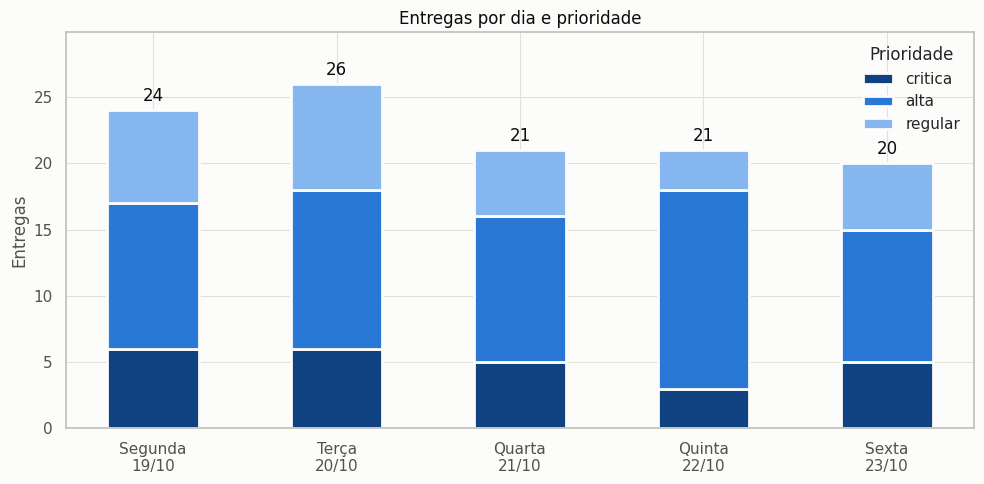

,priority,critica,alta,regular,total
date,weekday,,,,
2026-10-19,segunda-feira,6,11,7,24
2026-10-20,terça-feira,6,12,8,26
2026-10-21,quarta-feira,5,11,5,21
2026-10-22,quinta-feira,3,15,3,21
2026-10-23,sexta-feira,5,10,5,20


In [ ]:
# Entregas por dia, empilhadas por prioridade
daily_priority = deliveries.pivot_table(
    index=["date", "weekday"], columns="priority", values="location_id", aggfunc="count", fill_value=0
)[PRIORITY_ORDER]
day_labels = [f"{weekday.split('-')[0].capitalize()}\n{day[8:]}/{day[5:7]}" for day, weekday in daily_priority.index]

fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(daily_priority))
for priority in PRIORITY_ORDER:
    values = daily_priority[priority].to_numpy()
    ax.bar(day_labels, values, bottom=bottom, width=0.5, color=PRIORITY_COLORS[priority],
           edgecolor=SURFACE_COLOR, linewidth=2, label=priority)
    bottom += values
for x, total in enumerate(bottom):
    ax.text(x, total + 0.4, f"{int(total)}", ha="center", va="bottom", color=INK_COLOR)

ax.set_title("Entregas por dia e prioridade")
ax.set_ylabel("Entregas")
ax.set_ylim(0, bottom.max() * 1.15)
ax.legend(title="Prioridade", frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

daily_priority.assign(total=daily_priority.sum(axis=1))

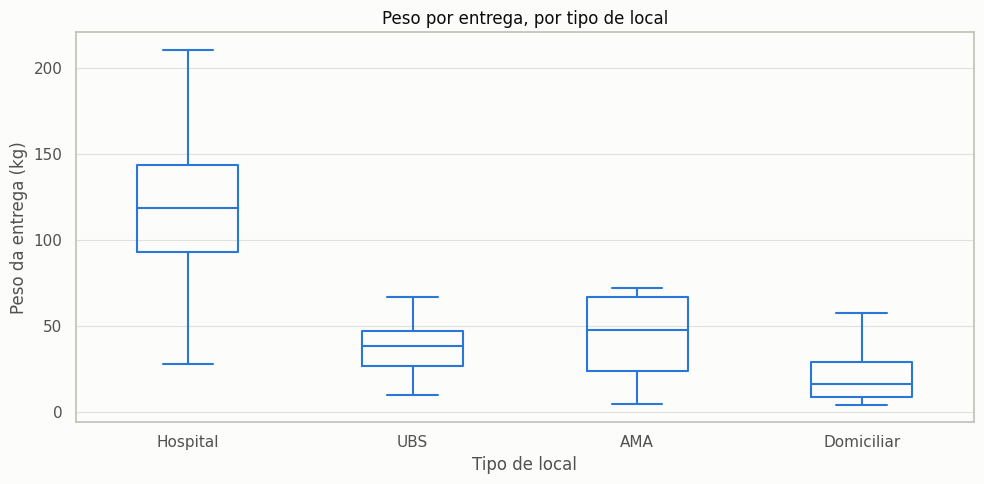

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
Hospital,32.0,121.2,44.2,27.8,93.4,118.6,143.9,210.6
UBS,45.0,38.3,14.7,10.0,26.9,38.4,47.0,67.3
AMA,10.0,44.4,26.1,5.0,24.0,48.0,67.2,72.0
Domiciliar,25.0,20.2,14.6,4.5,9.0,16.5,29.5,58.0


In [ ]:
# Peso por entrega, por tipo de local
type_order = ["Hospital", "UBS", "AMA", "Domiciliar"]

plt.figure(figsize=(10, 5))
sns.boxplot(data=deliveries, x="type", y="weight_kg", order=type_order, color=HIGHLIGHT_COLOR,
            fill=False, width=0.45, linewidth=1.5)
plt.title("Peso por entrega, por tipo de local")
plt.xlabel("Tipo de local")
plt.ylabel("Peso da entrega (kg)")
plt.tight_layout()
plt.show()

deliveries.groupby("type")["weight_kg"].describe().loc[type_order].round(1)

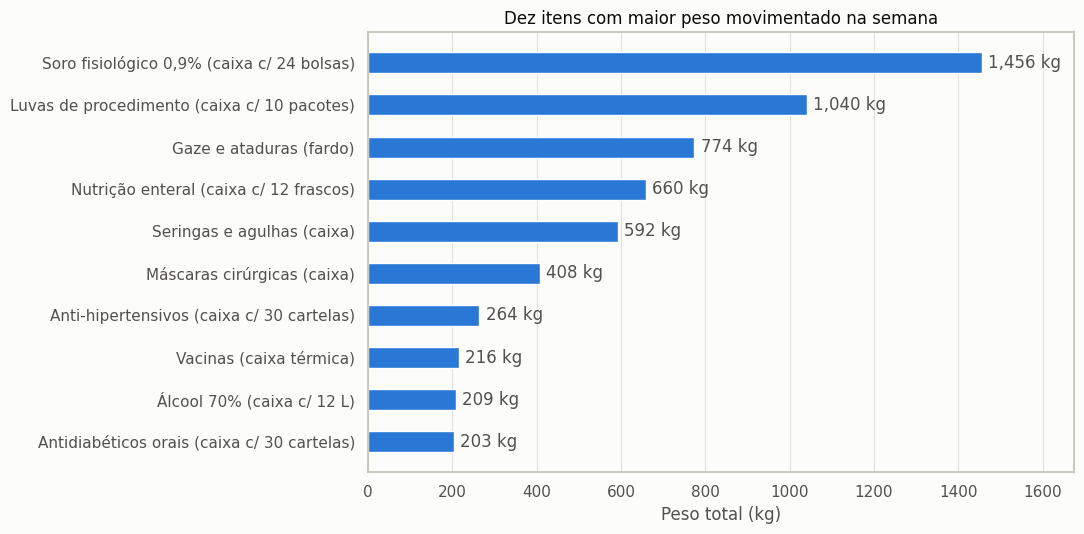

In [ ]:
# Itens com maior peso movimentado na semana
item_weight = orders.groupby("item")["weight_kg"].sum().sort_values().tail(10)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(item_weight.index, item_weight.values, height=0.5, color=HIGHLIGHT_COLOR)
for y, value in enumerate(item_weight.values):
    ax.text(value + item_weight.max() * 0.01, y, f"{value:,.0f} kg", va="center", color=INK_SECONDARY)
ax.set_title("Dez itens com maior peso movimentado na semana")
ax.set_xlabel("Peso total (kg)")
ax.set_xlim(0, item_weight.max() * 1.15)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [ ]:
# Volume diário, cadeia de frio e entregas críticas
daily_summary = deliveries.groupby(["date", "weekday"]).agg(
    entregas=("location_id", "count"),
    peso_total_kg=("weight_kg", "sum"),
    refrigeradas=("refrigerated", "sum"),
    peso_refrigerado_kg=("weight_kg", lambda s: s[deliveries.loc[s.index, "refrigerated"]].sum()),
    criticas=("priority", lambda s: int((s == "critica").sum())),
    controladas=("controlled", "sum"),
)
daily_summary["% refrigeradas"] = (daily_summary["refrigeradas"] / daily_summary["entregas"] * 100).round(1)
daily_summary["% da capacidade da frota"] = (daily_summary["peso_total_kg"] / fleet["capacity_kg"].sum() * 100).round(1)
daily_summary.round(1)

,,entregas,peso_total_kg,refrigeradas,peso_refrigerado_kg,criticas,controladas,% refrigeradas,% da capacidade da frota
date,weekday,,,,,,,,
2026-10-19,segunda-feira,24,1526.9,10,561.5,6,5,41.7,78.3
2026-10-20,terça-feira,26,1420.7,11,501.9,6,3,42.3,72.9
2026-10-21,quarta-feira,21,1205.5,12,599.2,5,3,57.1,61.8
2026-10-22,quinta-feira,21,1348.4,14,810.6,3,4,66.7,69.1
2026-10-23,sexta-feira,20,1050.6,9,443.0,5,2,45.0,53.9


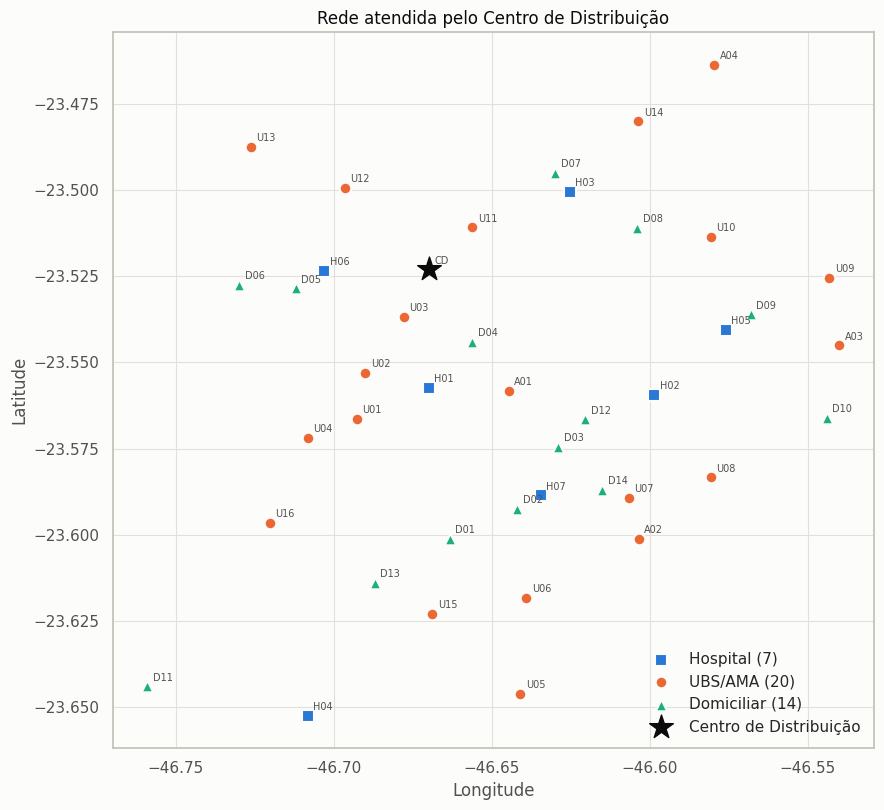

In [ ]:
# Localização da rede atendida
type_groups = {"Hospital": ["Hospital"], "UBS/AMA": ["UBS", "AMA"], "Domiciliar": ["Domiciliar"]}
type_markers = {"Hospital": "s", "UBS/AMA": "o", "Domiciliar": "^"}
depot_row = locations[locations["type"] == "Centro de Distribuição"].iloc[0]

fig, ax = plt.subplots(figsize=(9, 9))
for color, (label, types) in zip(SERIES_COLORS, type_groups.items()):
    subset = locations[locations["type"].isin(types)]
    ax.scatter(subset["longitude"], subset["latitude"], s=70, color=color, marker=type_markers[label],
               edgecolor=SURFACE_COLOR, linewidth=1.5, zorder=3, label=f"{label} ({len(subset)})")
ax.scatter(depot_row["longitude"], depot_row["latitude"], s=320, marker="*", color=INK_COLOR, zorder=4,
           label="Centro de Distribuição")
for row in locations.itertuples():
    ax.annotate(row.location_id, (row.longitude, row.latitude), xytext=(4, 4), textcoords="offset points",
                fontsize=7, color=INK_SECONDARY)

ax.set_aspect(1 / np.cos(np.radians(locations["latitude"].mean())))
ax.set_title("Rede atendida pelo Centro de Distribuição")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## Preparação do problema de roteamento

O dia analisado em detalhe é a segunda-feira, 19/10/2026, o de maior volume da semana. Cada entrega vira um nó do grafo e o nó 0 é o CD. As distâncias usam a fórmula de Haversine (distância sobre a superfície da Terra) multiplicada por um fator de tortuosidade de 1,3, aproximação usual para converter linha reta em distância por ruas em áreas urbanas. O tempo de deslocamento usa velocidade média de 24 km/h, típica do trânsito diurno de São Paulo, mais o tempo de atendimento de cada local (20 min em hospitais, 12 min em UBS/AMA e 15 min em domicílios).

Os prazos derivam da prioridade, contados a partir da saída às 07:00: entregas críticas até 2 h (09:00), de alta prioridade até 5 h (12:00) e regulares até o fim da jornada de 8 h (15:00), que também limita o retorno de cada veículo ao CD. A autonomia da frota é a distância máxima por turno, definida pela bateria do utilitário elétrico e pela política de abastecimento das vans.

In [ ]:
# Parâmetros operacionais
ANALYSIS_DAY = "2026-10-19"
DEPARTURE_TIME = "07:00"
AVG_SPEED_KMH = 24.0
ROAD_FACTOR = 1.3            # distância por ruas ≈ 1,3 × distância em linha reta
SHIFT_MIN = 480              # jornada máxima, incluindo o retorno ao CD (min)
TEAM_COST_PER_HOUR = 60.0    # motorista + auxiliar (R$/h), usado no custo operacional estimado

PRIORITY_DEADLINE_MIN = {"critica": 120, "alta": 300, "regular": SHIFT_MIN}
PRIORITY_WEIGHT = {"critica": 3.0, "alta": 1.5, "regular": 0.5}

WEEKDAY_BY_DATE = dict(orders[["date", "weekday"]].drop_duplicates().itertuples(index=False))
DEPARTURE = datetime.strptime(DEPARTURE_TIME, "%H:%M")


def clock(minutes_after_departure):
    """Converte minutos após a saída do CD em horário HH:MM."""
    return (DEPARTURE + timedelta(minutes=float(minutes_after_departure))).strftime("%H:%M")


print("Prazos por prioridade:", {priority: clock(minutes) for priority, minutes in PRIORITY_DEADLINE_MIN.items()})

Prazos por prioridade: {'critica': '09:00', 'alta': '12:00', 'regular': '15:00'}


In [ ]:
def build_day_nodes(day):
    """Nós de um dia: índice 0 = CD; demais = entregas consolidadas daquele dia."""
    day_stops = (
        deliveries[deliveries["date"] == day]
        .merge(locations[["location_id", "neighborhood", "latitude", "longitude", "service_time_min"]],
               on="location_id")
        .sort_values("location_id")
    )
    depot = locations[locations["type"] == "Centro de Distribuição"].assign(
        weight_kg=0.0, n_items=0, priority="regular", refrigerated=False, controlled=False
    )
    columns = ["location_id", "name", "type", "neighborhood", "zone", "latitude", "longitude",
               "service_time_min", "weight_kg", "n_items", "priority", "refrigerated", "controlled"]
    nodes = pd.concat([depot[columns], day_stops[columns]], ignore_index=True)
    nodes["deadline_min"] = nodes["priority"].map(PRIORITY_DEADLINE_MIN)
    return nodes


nodes = build_day_nodes(ANALYSIS_DAY)
print(f"{ANALYSIS_DAY} ({WEEKDAY_BY_DATE[ANALYSIS_DAY]}): {len(nodes) - 1} entregas | "
      f"{nodes['weight_kg'].sum():,.1f} kg | {int(nodes['refrigerated'].sum())} refrigeradas | "
      f"{int((nodes.loc[1:, 'priority'] == 'critica').sum())} críticas")
nodes.head(10)

2026-10-19 (segunda-feira): 24 entregas | 1,526.9 kg | 10 refrigeradas | 6 críticas


,location_id,name,type,neighborhood,zone,latitude,longitude,service_time_min,weight_kg,n_items,priority,refrigerated,controlled,deadline_min
0,CD,Centro de Distribuição - Hospital Universitário,Centro de Distribuição,Barra Funda,Oeste,-23.5230,-46.6700,0,0.0,0,regular,False,False,480
1,A04,AMA Jaçanã,AMA,Jaçanã,Norte,-23.4637,-46.5797,12,22.0,2,critica,False,False,120
2,D01,Paciente domiciliar 01,Domiciliar,Moema,Sul,-23.6012,-46.6633,15,29.5,3,alta,True,False,300
3,D02,Paciente domiciliar 02,Domiciliar,Vila Mariana,Sul,-23.5925,-46.6420,15,8.5,2,alta,True,False,300
4,D03,Paciente domiciliar 03,Domiciliar,Aclimação,Centro,-23.5745,-46.6290,15,34.0,4,critica,True,False,120
5,D08,Paciente domiciliar 08,Domiciliar,Vila Guilherme,Norte,-23.5110,-46.6040,15,9.0,1,critica,False,False,120
6,D11,Paciente domiciliar 11,Domiciliar,Campo Limpo,Sul,-23.6440,-46.7590,15,6.0,1,regular,False,False,480
7,H01,Hospital Universitário - Unidade Central,Hospital,Cerqueira César,Oeste,-23.5573,-46.6699,20,199.4,8,critica,False,True,120
8,H02,Hospital Dia Mooca,Hospital,Mooca,Leste,-23.5594,-46.5986,20,144.0,5,critica,False,False,120
9,H03,Pronto-Socorro Santana,Hospital,Santana,Norte,-23.5005,-46.6253,20,93.8,5,alta,False,True,300


In [ ]:
def haversine_matrix_km(latitudes, longitudes):
    """Distância de Haversine (km) entre todos os pares de coordenadas."""
    lat = np.radians(np.asarray(latitudes, dtype=float))
    lon = np.radians(np.asarray(longitudes, dtype=float))
    dlat = lat[:, None] - lat[None, :]
    dlon = lon[:, None] - lon[None, :]
    a = np.sin(dlat / 2) ** 2 + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(dlon / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


@dataclass
class RoutingProblem:
    """Dados de um dia de entregas em listas Python, para acesso rápido dentro do AG."""
    nodes: pd.DataFrame
    fleet: pd.DataFrame

    def __post_init__(self):
        self.n = len(self.nodes)
        road_km = haversine_matrix_km(self.nodes["latitude"], self.nodes["longitude"]) * ROAD_FACTOR
        self.dist = road_km.tolist()
        self.travel_min = (road_km * 60.0 / AVG_SPEED_KMH).tolist()
        self.codes = self.nodes["location_id"].tolist()
        self.demand = self.nodes["weight_kg"].tolist()
        self.service = self.nodes["service_time_min"].tolist()
        self.deadline = self.nodes["deadline_min"].tolist()
        self.priority = self.nodes["priority"].tolist()
        self.weight = [PRIORITY_WEIGHT[priority] for priority in self.priority]
        self.cold = self.nodes["refrigerated"].tolist()
        self.n_vehicles = len(self.fleet)
        self.vehicle_ids = self.fleet["vehicle_id"].tolist()
        self.capacity = self.fleet["capacity_kg"].tolist()
        self.autonomy = self.fleet["autonomy_km"].tolist()
        self.vehicle_cold = self.fleet["refrigerated"].tolist()
        self.cost_per_km = self.fleet["cost_per_km"].tolist()


problem = RoutingProblem(nodes, fleet)
cold_capacity = sum(cap for cap, cold in zip(problem.capacity, problem.vehicle_cold) if cold)
cold_demand = sum(dem for dem, cold in zip(problem.demand, problem.cold) if cold)

print(f"Nós: {problem.n} (CD + {problem.n - 1} entregas) | veículos: {problem.n_vehicles}")
print(f"Demanda total      : {sum(problem.demand):,.1f} kg de {sum(problem.capacity):,} kg de capacidade")
print(f"Demanda refrigerada: {cold_demand:,.1f} kg de {cold_capacity:,} kg em veículos refrigerados")
print(f"Maior distância entre dois nós: {np.max(problem.dist):.1f} km | média até o CD: {np.mean(problem.dist[0][1:]):.1f} km")

Nós: 25 (CD + 24 entregas) | veículos: 3
Demanda total      : 1,526.9 kg de 1,950 kg de capacidade
Demanda refrigerada: 561.5 kg de 1,050 kg em veículos refrigerados
Maior distância entre dois nós: 35.3 km | média até o CD: 10.8 km


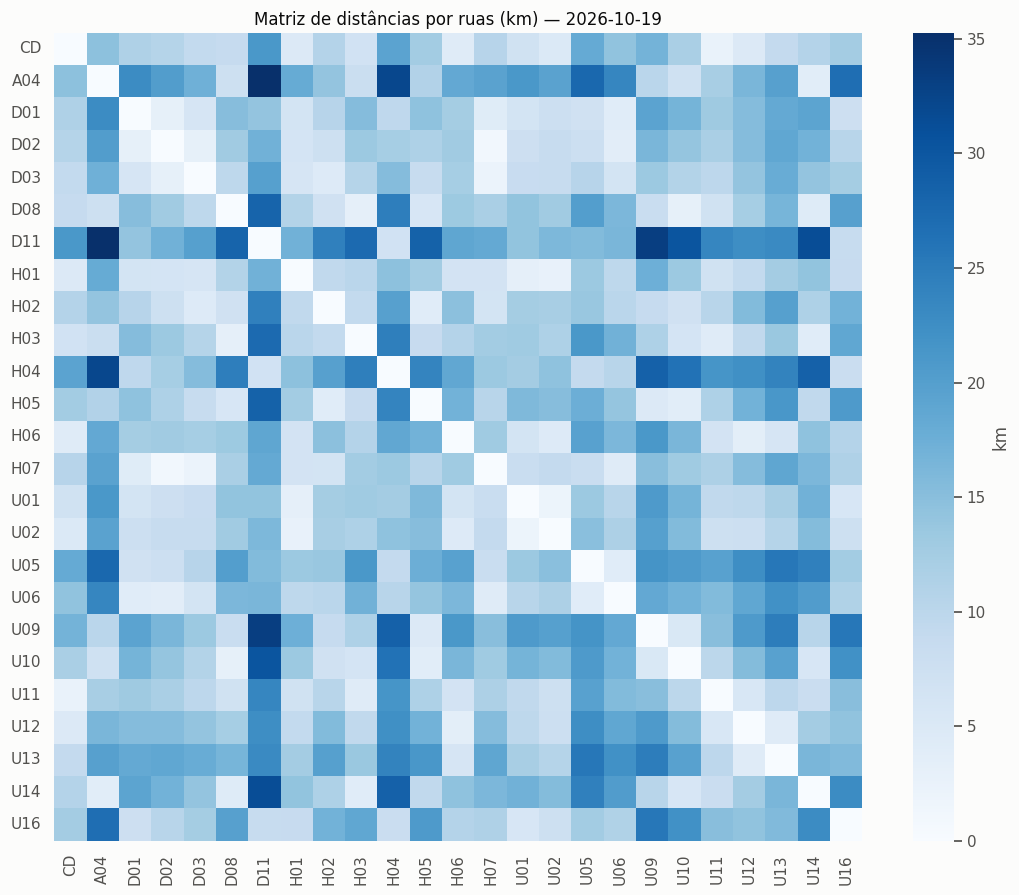

In [ ]:
# Matriz de distâncias estimadas por ruas
plt.figure(figsize=(11, 9))
sns.heatmap(pd.DataFrame(problem.dist, index=problem.codes, columns=problem.codes),
            cmap="Blues", square=True, cbar_kws={"label": "km"})
plt.title(f"Matriz de distâncias por ruas (km) — {ANALYSIS_DAY}")
plt.tight_layout()
plt.show()

## Código base: TSP com algoritmo genético

O ponto de partida é um TSP genético clássico, no formato do código base fornecido: população inicial de permutações aleatórias (`generate_random_population`), fitness igual ao comprimento do circuito fechado — quanto menor, melhor (`calculate_fitness`), Order Crossover (`order_crossover`), mutação que troca duas cidades vizinhas (`mutate`), ordenação da população (`sort_population`) e um laço com elitismo de 1 indivíduo e seleção por roleta com probabilidade proporcional a 1/fitness. A única adaptação nesta etapa é trocar coordenadas em pixels por índices de nós e a distância euclidiana pela matriz de distâncias por ruas; o circuito inclui o CD para começar e terminar nele. Se o arquivo entregue pela disciplina tiver diferenças de detalhe, os pontos de extensão para o VRP são os mesmos.

In [ ]:
# Código base (TSP clássico): cromossomo = permutação de todos os nós, inclusive o CD
def generate_random_population(cities, population_size):
    return [random.sample(cities, len(cities)) for _ in range(population_size)]


def calculate_distance(point1, point2):
    return problem.dist[point1][point2]


def calculate_fitness(path):
    # Circuito fechado: a última cidade volta para a primeira
    return sum(calculate_distance(path[i], path[(i + 1) % len(path)]) for i in range(len(path)))


def order_crossover(parent1, parent2):
    length = len(parent1)
    start_index = random.randint(0, length - 1)
    end_index = random.randint(start_index + 1, length)
    child = parent1[start_index:end_index]
    remaining_positions = [i for i in range(length) if i < start_index or i >= end_index]
    remaining_genes = [gene for gene in parent2 if gene not in child]
    for position, gene in zip(remaining_positions, remaining_genes):
        child.insert(position, gene)
    return child


def mutate(solution, mutation_probability):
    mutated_solution = solution[:]
    if random.random() < mutation_probability and len(solution) >= 2:
        index = random.randint(0, len(solution) - 2)
        mutated_solution[index], mutated_solution[index + 1] = solution[index + 1], solution[index]
    return mutated_solution


def sort_population(population, fitness):
    combined = sorted(zip(population, fitness), key=lambda pair: pair[1])
    sorted_population, sorted_fitness = zip(*combined)
    return list(sorted_population), list(sorted_fitness)

In [ ]:
# Laço principal do código base: elitismo de 1 indivíduo + roleta proporcional a 1/fitness
TSP_POPULATION_SIZE = 100
TSP_GENERATIONS = 600
TSP_MUTATION_PROBABILITY = 0.5

random.seed(SEED)
cities = list(range(problem.n))
population = generate_random_population(cities, TSP_POPULATION_SIZE)
tsp_best_fitness = []
tsp_started = time.perf_counter()

for generation in range(TSP_GENERATIONS):
    population_fitness = [calculate_fitness(individual) for individual in population]
    population, population_fitness = sort_population(population, population_fitness)
    tsp_best_fitness.append(population_fitness[0])

    new_population = [population[0]]  # elitismo
    probability = 1 / np.array(population_fitness)
    while len(new_population) < TSP_POPULATION_SIZE:
        parent1, parent2 = random.choices(population, weights=probability, k=2)
        child = order_crossover(parent1, parent2)
        child = mutate(child, TSP_MUTATION_PROBABILITY)
        new_population.append(child)
    population = new_population

population_fitness = [calculate_fitness(individual) for individual in population]
population, population_fitness = sort_population(population, population_fitness)
tsp_runtime = time.perf_counter() - tsp_started

# Gira o circuito para começar e terminar no CD
tsp_tour = population[0]
depot_position = tsp_tour.index(0)
tsp_route = tsp_tour[depot_position + 1:] + tsp_tour[:depot_position]

print(f"Melhor circuito na geração 1  : {tsp_best_fitness[0]:.1f} km")
print(f"Melhor circuito na geração {TSP_GENERATIONS}: {population_fitness[0]:.1f} km ({tsp_runtime:.1f} s)")
print("Sequência:", " → ".join(problem.codes[node] for node in [0, *tsp_route, 0]))

Melhor circuito na geração 1  : 262.4 km
Melhor circuito na geração 600: 156.5 km (7.3 s)
Sequência: CD → U11 → H03 → U14 → D08 → H05 → U09 → U10 → A04 → H02 → D03 → H01 → U02 → U12 → U13 → H06 → U01 → D02 → H07 → U06 → U05 → U16 → D11 → H04 → D01 → CD


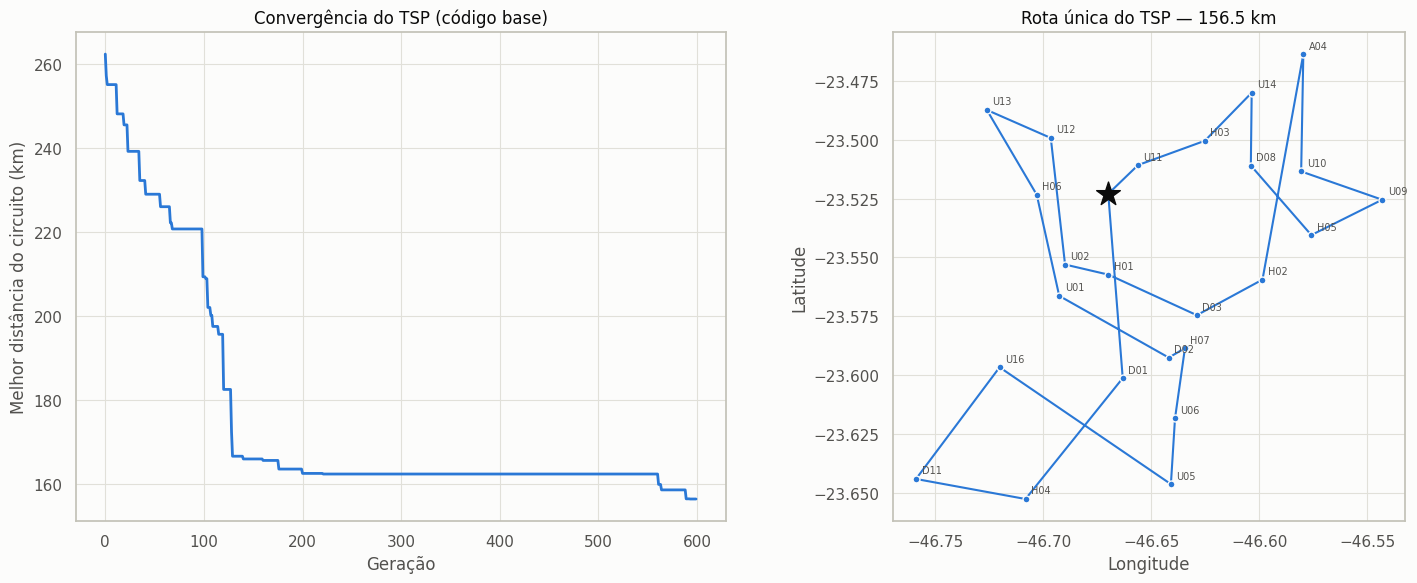

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].plot(tsp_best_fitness, color=HIGHLIGHT_COLOR)
axes[0].set_title("Convergência do TSP (código base)")
axes[0].set_xlabel("Geração")
axes[0].set_ylabel("Melhor distância do circuito (km)")

tour = [0, *tsp_route, 0]
axes[1].plot(nodes.loc[tour, "longitude"], nodes.loc[tour, "latitude"], color=HIGHLIGHT_COLOR, linewidth=1.5,
             marker="o", markersize=5, markeredgecolor=SURFACE_COLOR)
axes[1].scatter(nodes.loc[0, "longitude"], nodes.loc[0, "latitude"], s=320, marker="*", color=INK_COLOR, zorder=4)
for node in tsp_route:
    axes[1].annotate(problem.codes[node], (nodes.loc[node, "longitude"], nodes.loc[node, "latitude"]),
                     xytext=(4, 4), textcoords="offset points", fontsize=7, color=INK_SECONDARY)
axes[1].set_aspect(1 / np.cos(np.radians(nodes["latitude"].mean())))
axes[1].set_title(f"Rota única do TSP — {population_fitness[0]:.1f} km")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

## Do TSP ao VRP: representação genética e função fitness

**Representação.** O cromossomo passa a ser uma permutação das entregas intercalada com `K − 1` genes separadores (números negativos), em que `K` é o número de veículos. Os separadores dividem a permutação em `K` trechos: o trecho *k* é a rota do veículo *k*, que sempre sai do CD e volta a ele. Com 3 veículos, `[5, 2, -1, 7, 1, -2, 3, 6, 4]` significa VAN-REF-01: CD → 5 → 2 → CD; VAN-02: CD → 7 → 1 → CD; UTIL-REF-03: CD → 3 → 6 → 4 → CD. Como os separadores são genes comuns, o Order Crossover e as mutações continuam gerando cromossomos válidos sem reparo: mover um separador transfere entregas entre veículos, e um trecho vazio significa veículo parado.

**Fitness (custo a minimizar).** Cada rota é simulada no tempo: a chegada em uma parada é a soma dos deslocamentos e atendimentos anteriores. O custo, em km equivalentes, é

$$\text{custo} = \sum_k d_k \;+\; \alpha \sum_i w_i \frac{t_i}{60} \;+\; \beta \sum_i w_i \max(0,\, t_i - p_i) \;+\; \lambda_c \sum_k \max(0,\, q_k - Q_k) \;+\; \lambda_a \sum_k \max(0,\, d_k - A_k) \;+\; \lambda_j \sum_k \max(0,\, T_k - J) \;+\; \lambda_f\, n_{\text{frio}}$$

- $d_k$, $q_k$ e $T_k$: distância, carga e duração da rota do veículo *k*; $Q_k$ e $A_k$: capacidade e autonomia; $J$: jornada de 480 min.
- $t_i$ e $p_i$: chegada e prazo da entrega *i*, em minutos após a saída; $w_i$: peso da prioridade (crítica 3; alta 1,5; regular 0,5).
- O termo $\alpha$ = 2 km por hora ponderada é a **prioridade suave**: antecipa as entregas críticas mesmo quando o prazo não está ameaçado. O termo $\beta$ = 1 por minuto ponderado pune atrasos.
- Os termos $\lambda$ são **penalidades** das restrições rígidas: excesso de carga (2 por kg), de autonomia (10 por km), de jornada (2 por min) e entrega refrigerada em veículo sem refrigeração (200 por ocorrência, $n_{\text{frio}}$). Penalizar em vez de descartar deixa o AG atravessar regiões inviáveis rumo a soluções viáveis melhores; as penalidades são grandes o suficiente para que nenhuma solução inviável compense.

In [ ]:
# Pesos da função fitness (unidade: km equivalentes)
ALPHA_PRIORITY = 2.0         # por hora de espera, ponderada pela prioridade
BETA_LATE = 1.0              # por minuto de atraso, ponderado pela prioridade
PENALTY_CAPACITY = 2.0       # por kg acima da capacidade
PENALTY_AUTONOMY = 10.0      # por km acima da autonomia
PENALTY_SHIFT = 2.0          # por minuto acima da jornada
PENALTY_COLD_CHAIN = 200.0   # por entrega refrigerada em veículo sem refrigeração


def decode(chromosome, n_vehicles):
    """Separa o cromossomo em uma rota por veículo (genes negativos são separadores)."""
    routes = [[] for _ in range(n_vehicles)]
    k = 0
    for gene in chromosome:
        if gene < 0:
            k += 1
        else:
            routes[k].append(gene)
    return routes


def encode(routes):
    """Operação inversa: concatena as rotas inserindo os separadores -1, -2, ..."""
    chromosome = []
    for k, route in enumerate(routes):
        if k > 0:
            chromosome.append(-k)
        chromosome.extend(route)
    return chromosome


def route_cost(problem, route, k):
    """Custo de uma rota do veículo k: distância + prioridade + penalidades (versão rápida do AG)."""
    dist, travel = problem.dist, problem.travel_min
    prev = 0
    distance = elapsed = load = waiting = lateness = 0.0
    cold_violations = 0
    for stop in route:
        distance += dist[prev][stop]
        elapsed += travel[prev][stop]
        weight = problem.weight[stop]
        waiting += weight * elapsed
        if elapsed > problem.deadline[stop]:
            lateness += weight * (elapsed - problem.deadline[stop])
        elapsed += problem.service[stop]
        load += problem.demand[stop]
        if problem.cold[stop] and not problem.vehicle_cold[k]:
            cold_violations += 1
        prev = stop
    distance += dist[prev][0]
    elapsed += travel[prev][0]
    return (
        distance
        + ALPHA_PRIORITY * waiting / 60.0
        + BETA_LATE * lateness
        + PENALTY_CAPACITY * max(0.0, load - problem.capacity[k])
        + PENALTY_AUTONOMY * max(0.0, distance - problem.autonomy[k])
        + PENALTY_SHIFT * max(0.0, elapsed - SHIFT_MIN)
        + PENALTY_COLD_CHAIN * cold_violations
    )


def chromosome_cost(problem, chromosome):
    """Fitness do cromossomo: soma dos custos das rotas, decodificando em uma única passada."""
    total, route, k = 0.0, [], 0
    for gene in chromosome:
        if gene < 0:
            total += route_cost(problem, route, k)
            route, k = [], k + 1
        else:
            route.append(gene)
    return total + route_cost(problem, route, k)

In [ ]:
def simulate_route(problem, route, k):
    """Linha do tempo detalhada de uma rota: chegada, folga até o prazo e carga acumulada."""
    stops = []
    prev, distance, elapsed, load = 0, 0.0, 0.0, 0.0
    for seq, node in enumerate(route, start=1):
        distance += problem.dist[prev][node]
        elapsed += problem.travel_min[prev][node]
        load += problem.demand[node]
        stops.append({
            "vehicle_id": problem.vehicle_ids[k], "seq": seq, "node": node, "code": problem.codes[node],
            "priority": problem.priority[node], "weight": problem.weight[node],
            "arrival_min": elapsed, "deadline_min": problem.deadline[node],
            "slack_min": problem.deadline[node] - elapsed,
            "cold_violation": bool(problem.cold[node] and not problem.vehicle_cold[k]),
        })
        elapsed += problem.service[node]
        prev = node
    if route:
        distance += problem.dist[prev][0]
        elapsed += problem.travel_min[prev][0]
    return stops, distance, elapsed, load


def evaluate_solution(problem, routes):
    """Recalcula a solução por simulação detalhada e resume indicadores, custos e violações."""
    vehicle_rows, stop_rows = [], []
    for k, route in enumerate(routes):
        stops, distance, duration, load = simulate_route(problem, route, k)
        stop_rows += stops
        vehicle_rows.append({
            "vehicle_id": problem.vehicle_ids[k], "stops": len(route),
            "distance_km": distance, "duration_min": duration, "load_kg": load,
            "capacity_kg": problem.capacity[k], "autonomy_km": problem.autonomy[k],
            "capacity_excess_kg": max(0.0, load - problem.capacity[k]),
            "autonomy_excess_km": max(0.0, distance - problem.autonomy[k]),
            "shift_excess_min": max(0.0, duration - SHIFT_MIN),
            "cost_rs": distance * problem.cost_per_km[k] + duration / 60 * TEAM_COST_PER_HOUR,
        })
    vehicles = pd.DataFrame(vehicle_rows)
    stops = pd.DataFrame(stop_rows)
    lateness = (-stops["slack_min"]).clip(lower=0)
    cold_violations = int(stops["cold_violation"].sum())
    cost = (
        vehicles["distance_km"].sum()
        + ALPHA_PRIORITY * (stops["weight"] * stops["arrival_min"]).sum() / 60
        + BETA_LATE * (stops["weight"] * lateness).sum()
        + PENALTY_CAPACITY * vehicles["capacity_excess_kg"].sum()
        + PENALTY_AUTONOMY * vehicles["autonomy_excess_km"].sum()
        + PENALTY_SHIFT * vehicles["shift_excess_min"].sum()
        + PENALTY_COLD_CHAIN * cold_violations
    )
    violations = (int((vehicles["capacity_excess_kg"] > 0).sum()) + int((vehicles["autonomy_excess_km"] > 0).sum())
                  + int((vehicles["shift_excess_min"] > 0).sum()) + cold_violations)

    def on_time(priority=None):
        subset = stops if priority is None else stops[stops["priority"] == priority]
        return float((subset["slack_min"] >= 0).mean()) if len(subset) else 1.0

    return {
        "cost": cost,
        "distance_km": vehicles["distance_km"].sum(),
        "duration_h": vehicles["duration_min"].sum() / 60,
        "cost_rs": vehicles["cost_rs"].sum(),
        "vehicles_used": int((vehicles["stops"] > 0).sum()),
        "makespan_min": vehicles["duration_min"].max(),
        "critical_on_time": on_time("critica"),
        "high_on_time": on_time("alta"),
        "all_on_time": on_time(),
        "critical_total": int((stops["priority"] == "critica").sum()),
        "critical_late": int(((stops["priority"] == "critica") & (stops["slack_min"] < 0)).sum()),
        "capacity_excess_kg": vehicles["capacity_excess_kg"].sum(),
        "autonomy_excess_km": vehicles["autonomy_excess_km"].sum(),
        "shift_excess_min": vehicles["shift_excess_min"].sum(),
        "cold_violations": cold_violations,
        "violations": violations,
        "feasible": violations == 0,
        "vehicles": vehicles,
        "stops": stops,
    }

In [ ]:
# Testes rápidos da modelagem
example_routes = [[5, 2], [7, 1], [3, 6, 4]]
assert decode([5, 2, -1, 7, 1, -2, 3, 6, 4], 3) == example_routes
assert decode(encode(example_routes), 3) == example_routes
assert decode([-1, -2, 4, 2], 3) == [[], [], [4, 2]]   # veículos vazios são permitidos

test_rng = random.Random(SEED)
all_genes = list(range(1, problem.n)) + [-(k + 1) for k in range(problem.n_vehicles - 1)]
for _ in range(300):
    chromosome = test_rng.sample(all_genes, len(all_genes))
    routes = decode(chromosome, problem.n_vehicles)
    # Cada entrega aparece exatamente uma vez e as duas implementações da fitness concordam
    assert sorted(node for route in routes for node in route) == list(range(1, problem.n))
    assert math.isclose(chromosome_cost(problem, chromosome), evaluate_solution(problem, routes)["cost"], rel_tol=1e-9)

print("Testes de codificação e de consistência da fitness: OK (300 cromossomos aleatórios)")

Testes de codificação e de consistência da fitness: OK (300 cromossomos aleatórios)


## O TSP do código base diante das restrições reais

A função `record_result` avalia qualquer solução com a mesma simulação, exibe os indicadores e acumula o resultado na lista `results`, usada na comparação final. O primeiro registro é o circuito do código base colocado inteiro no veículo de maior capacidade (VAN-02): ele mostra por que o TSP puro não atende a operação.

In [ ]:
results = []  # recolhe um dicionário por abordagem


def record_result(name, routes, runtime_s, problem=problem, results_list=results):
    """Avalia uma solução, exibe os indicadores e guarda o resultado para a comparação final."""
    evaluation = evaluate_solution(problem, routes)
    results_list.append({
        "Abordagem": name,
        "Custo (fitness)": evaluation["cost"],
        "Distância (km)": evaluation["distance_km"],
        "Tempo em rota (h)": evaluation["duration_h"],
        "Custo estimado (R$)": evaluation["cost_rs"],
        "Veículos": evaluation["vehicles_used"],
        "Críticas no prazo": evaluation["critical_on_time"],
        "Alta no prazo": evaluation["high_on_time"],
        "Violações": evaluation["violations"],
        "Tempo de execução (s)": runtime_s,
    })

    print(f"📌 {name}")
    print(f"Custo (fitness)     : {evaluation['cost']:,.1f}")
    print(f"Distância total     : {evaluation['distance_km']:.1f} km | tempo em rota: {evaluation['duration_h']:.1f} h")
    print(f"Custo estimado      : R$ {evaluation['cost_rs']:,.2f}")
    print(f"Críticas no prazo   : {evaluation['critical_total'] - evaluation['critical_late']}/{evaluation['critical_total']}"
          f" | alta no prazo: {evaluation['high_on_time']:.0%}")
    print(f"Violações           : {evaluation['violations']} (carga +{evaluation['capacity_excess_kg']:.0f} kg, "
          f"autonomia +{evaluation['autonomy_excess_km']:.1f} km, jornada +{evaluation['shift_excess_min']:.0f} min, "
          f"cadeia de frio {evaluation['cold_violations']})")
    print("-" * 50)
    return evaluation

In [ ]:
largest_vehicle = int(np.argmax(problem.capacity))
tsp_routes = [[] for _ in range(problem.n_vehicles)]
tsp_routes[largest_vehicle] = tsp_route

tsp_eval = record_result(f"TSP do código base (só {problem.vehicle_ids[largest_vehicle]})", tsp_routes, tsp_runtime)

📌 TSP do código base (só VAN-02)
Custo (fitness)     : 9,849.7
Distância total     : 156.5 km | tempo em rota: 12.5 h
Custo estimado      : R$ 961.48
Críticas no prazo   : 1/6 | alta no prazo: 36%
Violações           : 13 (carga +627 kg, autonomia +6.5 km, jornada +270 min, cadeia de frio 10)
--------------------------------------------------


O circuito mais curto não serve à operação: a carga do dia não cabe em um veículo, a jornada estoura, entregas refrigeradas viajariam sem refrigeração e boa parte das críticas chegaria atrasada. É preciso dividir as entregas entre veículos respeitando todas as restrições — o problema de roteamento de veículos (VRP).

## Abordagens de comparação

Para medir o ganho do AG, as mesmas entregas são roteadas por outras abordagens, todas avaliadas pela mesma simulação e pela mesma função de custo:

- **Aleatória**: melhor de 1.000 cromossomos sorteados, referência do ponto de partida do AG.
- **Vizinho mais próximo (VMP)**: heurística gulosa que monta uma rota por vez, começando pelo veículo de carga seca, sempre indo à entrega viável mais próxima (carga, autonomia, jornada e cadeia de frio checadas a cada passo). O que sobrar é inserido onde aumenta menos a distância.
- **Despacho por prioridade**: mesma lógica, mas atende todas as críticas antes das de alta prioridade e estas antes das regulares — regra manual comum em centrais de distribuição.
- **VMP + 2-opt**: as rotas do VMP refinadas pela busca local 2-opt, que inverte trechos da rota enquanto a distância diminuir (melhoria clássica do TSP).

In [ ]:
def greedy_routes(problem, priority_first=False):
    """Vizinho mais próximo com restrições; priority_first=True atende críticas, depois alta, depois regular."""
    dist, travel = problem.dist, problem.travel_min
    pending = set(range(1, problem.n))
    routes = [[] for _ in range(problem.n_vehicles)]
    vehicle_order = sorted(range(problem.n_vehicles), key=lambda k: (problem.vehicle_cold[k], -problem.capacity[k]))

    for k in vehicle_order:
        position, load, distance, elapsed = 0, 0.0, 0.0, 0.0
        while True:
            candidates = [
                stop for stop in pending
                if (problem.vehicle_cold[k] or not problem.cold[stop])
                and load + problem.demand[stop] <= problem.capacity[k]
                and distance + dist[position][stop] + dist[stop][0] <= problem.autonomy[k]
                and elapsed + travel[position][stop] + problem.service[stop] + travel[stop][0] <= SHIFT_MIN
            ]
            if not candidates:
                break
            if priority_first:
                top = min(PRIORITY_RANK[problem.priority[stop]] for stop in candidates)
                candidates = [stop for stop in candidates if PRIORITY_RANK[problem.priority[stop]] == top]
            nearest = min(candidates, key=lambda stop: dist[position][stop])
            routes[k].append(nearest)
            pending.remove(nearest)
            load += problem.demand[nearest]
            distance += dist[position][nearest]
            elapsed += travel[position][nearest] + problem.service[nearest]
            position = nearest

    # Entregas que não couberam: inserção mais barata em um veículo compatível (pode violar restrições)
    for stop in sorted(pending):
        options = [
            (dist[route[i - 1] if i else 0][stop] + dist[stop][route[i] if i < len(route) else 0]
             - dist[route[i - 1] if i else 0][route[i] if i < len(route) else 0], k, i)
            for k, route in enumerate(routes) if problem.vehicle_cold[k] or not problem.cold[stop]
            for i in range(len(route) + 1)
        ]
        _, k, i = min(options)
        routes[k].insert(i, stop)
    return routes


def two_opt(problem, route):
    """Busca local 2-opt: inverte trechos da rota enquanto a distância diminuir."""
    dist = problem.dist
    best = route[:]
    improved = True
    while improved:
        improved = False
        for i in range(len(best) - 1):
            for j in range(i + 1, len(best)):
                a = best[i - 1] if i > 0 else 0
                b, c = best[i], best[j]
                d = best[j + 1] if j + 1 < len(best) else 0
                if dist[a][c] + dist[b][d] - dist[a][b] - dist[c][d] < -1e-9:
                    best[i:j + 1] = best[i:j + 1][::-1]
                    improved = True
    return best


def heuristic_solutions(problem):
    """Soluções heurísticas do dia (também usadas para semear o AG híbrido)."""
    nearest = greedy_routes(problem)
    by_priority = greedy_routes(problem, priority_first=True)
    nearest_2opt = [two_opt(problem, route) for route in nearest]
    return {"nearest": nearest, "priority": by_priority, "nearest_2opt": nearest_2opt}

In [ ]:
# Aleatória: melhor de 1.000 cromossomos
started = time.perf_counter()
random_rng = random.Random(SEED)
random_best = min((random_rng.sample(all_genes, len(all_genes)) for _ in range(1000)),
                  key=lambda chromosome: chromosome_cost(problem, chromosome))
random_eval = record_result("Aleatória (melhor de 1.000)", decode(random_best, problem.n_vehicles),
                            time.perf_counter() - started)

📌 Aleatória (melhor de 1.000)
Custo (fitness)     : 2,197.1
Distância total     : 325.9 km | tempo em rota: 19.6 h
Custo estimado      : R$ 1,599.86
Críticas no prazo   : 4/6 | alta no prazo: 82%
Violações           : 5 (carga +175 kg, autonomia +11.7 km, jornada +66 min, cadeia de frio 2)
--------------------------------------------------


In [ ]:
# Heurísticas construtivas e busca local
started = time.perf_counter()
heuristics = heuristic_solutions(problem)
heuristics_runtime = time.perf_counter() - started

nn_eval = record_result("Vizinho mais próximo", heuristics["nearest"], heuristics_runtime)
priority_eval = record_result("Despacho por prioridade", heuristics["priority"], heuristics_runtime)
nn_2opt_eval = record_result("Vizinho mais próximo + 2-opt", heuristics["nearest_2opt"], heuristics_runtime)

📌 Vizinho mais próximo
Custo (fitness)     : 974.9
Distância total     : 229.6 km | tempo em rota: 15.5 h
Custo estimado      : R$ 1,273.75
Críticas no prazo   : 3/6 | alta no prazo: 91%
Violações           : 0 (carga +0 kg, autonomia +0.0 km, jornada +0 min, cadeia de frio 0)
--------------------------------------------------
📌 Despacho por prioridade
Custo (fitness)     : 453.5
Distância total     : 226.9 km | tempo em rota: 15.4 h
Custo estimado      : R$ 1,291.59
Críticas no prazo   : 5/6 | alta no prazo: 91%
Violações           : 0 (carga +0 kg, autonomia +0.0 km, jornada +0 min, cadeia de frio 0)
--------------------------------------------------
📌 Vizinho mais próximo + 2-opt
Custo (fitness)     : 2,654.2
Distância total     : 191.1 km | tempo em rota: 13.9 h
Custo estimado      : R$ 1,118.37
Críticas no prazo   : 1/6 | alta no prazo: 73%
Violações           : 0 (carga +0 kg, autonomia +0.0 km, jornada +0 min, cadeia de frio 0)
--------------------------------------------------


## Operadores genéticos especializados

- **Seleção por roleta** (código base): probabilidade proporcional a 1/custo. Com penalidades, os custos da população ficam muito próximos em termos relativos e a pressão seletiva quase desaparece.
- **Seleção por torneio**: sorteia *k* indivíduos e vence o de menor custo. A pressão seletiva é ajustada por *k* e não depende da escala do custo.
- **Order Crossover (OX)**: copia um trecho contíguo do pai 1 e completa com os genes restantes na ordem em que aparecem no pai 2. Preserva sequências de visitas e a validade da permutação, inclusive dos separadores.
- **Mutações**: *troca adjacente* (código base); *troca* de dois genes quaisquer; *inversão* de um trecho, equivalente a um movimento 2-opt que desfaz cruzamentos de rota; *inserção*, que retira uma entrega e a recoloca em outra posição — possivelmente em outro veículo.
- **Elitismo**: os melhores indivíduos passam intactos para a geração seguinte, então o melhor custo nunca piora.
- **Semeadura (AG híbrido)**: parte da população inicial recebe as soluções heurísticas (VMP, despacho por prioridade e VMP + 2-opt); o restante é aleatório.

In [ ]:
def crossover_ox(parent1, parent2, rng):
    """Order Crossover: trecho do pai 1 + genes restantes na ordem do pai 2."""
    length = len(parent1)
    start = rng.randint(0, length - 1)
    end = rng.randint(start + 1, length)
    segment = parent1[start:end]
    in_segment = set(segment)
    remaining = [gene for gene in parent2 if gene not in in_segment]
    return remaining[:start] + segment + remaining[start:]


def mutate_routes(chromosome, mutation_rate, operators, rng):
    """Aplica, com probabilidade mutation_rate, um dos operadores de mutação sorteado."""
    if rng.random() >= mutation_rate:
        return chromosome
    child = chromosome[:]
    operator = rng.choice(operators)
    if operator == "adjacent_swap":
        i = rng.randint(0, len(child) - 2)
        child[i], child[i + 1] = child[i + 1], child[i]
    elif operator == "swap":
        i, j = rng.sample(range(len(child)), 2)
        child[i], child[j] = child[j], child[i]
    elif operator == "inversion":
        i, j = sorted(rng.sample(range(len(child)), 2))
        child[i:j + 1] = child[i:j + 1][::-1]
    elif operator == "insertion":
        i, j = rng.sample(range(len(child)), 2)
        child.insert(j, child.pop(i))
    return child


@dataclass
class GAConfig:
    name: str
    population_size: int = 150
    generations: int = 600
    selection: str = "tournament"        # "tournament" ou "roulette"
    tournament_size: int = 3
    crossover_rate: float = 0.9
    mutation_rate: float = 0.3
    mutation_operators: tuple = ("swap", "inversion", "insertion")
    elite_size: int = 3
    seeded: bool = False                 # semeia a população com as soluções heurísticas


def run_ga(problem, config, seed, heuristic_routes=()):
    """Executa o AG para o VRP e devolve a melhor solução e o histórico de convergência."""
    rng = random.Random(seed)
    genes = list(range(1, problem.n)) + [-(k + 1) for k in range(problem.n_vehicles - 1)]
    population = [rng.sample(genes, len(genes)) for _ in range(config.population_size)]
    if config.seeded:
        for i, routes in enumerate(heuristic_routes):
            population[i] = encode(routes)
    costs = [chromosome_cost(problem, chromosome) for chromosome in population]
    evaluations = len(population)
    best_history, mean_history = [], []
    started = time.perf_counter()

    for _ in range(config.generations):
        ranking = sorted(range(len(population)), key=costs.__getitem__)
        population = [population[i] for i in ranking]
        costs = [costs[i] for i in ranking]
        best_history.append(costs[0])
        mean_history.append(sum(costs) / len(costs))

        if config.selection == "roulette":
            cum_weights = list(itertools.accumulate(1.0 / cost for cost in costs))

            def select():
                return rng.choices(population, cum_weights=cum_weights, k=1)[0]
        else:
            def select():
                # A população está ordenada por custo: o menor índice sorteado vence o torneio
                return population[min(rng.sample(range(len(population)), config.tournament_size))]

        next_population = [chromosome[:] for chromosome in population[:config.elite_size]]
        next_costs = costs[:config.elite_size]
        while len(next_population) < config.population_size:
            parent1, parent2 = select(), select()
            if rng.random() < config.crossover_rate:
                child = crossover_ox(parent1, parent2, rng)
            else:
                child = parent1[:]
            child = mutate_routes(child, config.mutation_rate, config.mutation_operators, rng)
            next_population.append(child)
            next_costs.append(chromosome_cost(problem, child))
        evaluations += config.population_size - config.elite_size
        population, costs = next_population, next_costs

    best = min(range(len(population)), key=costs.__getitem__)
    best_history.append(costs[best])
    return {
        "config": config.name, "seed": seed, "chromosome": population[best],
        "routes": decode(population[best], problem.n_vehicles), "cost": costs[best],
        "best_history": best_history, "mean_history": mean_history,
        "runtime_s": time.perf_counter() - started, "evaluations": evaluations,
    }

## Experimentos com diferentes configurações do AG

| Experimento | População | Seleção | Cruzamento | Mutação | Elitismo | População inicial |
|---|---|---|---|---|---|---|
| E1 · Base adaptado | 100 | Roleta (1/custo) | OX, taxa 1,0 | troca adjacente, taxa 0,5 | 1 | aleatória |
| E2 · Torneio + mutação mista | 150 | Torneio (k = 3) | OX, taxa 0,9 | troca, inversão e inserção, taxa 0,3 | 3 | aleatória |
| E3 · População maior + mutação alta | 300 | Torneio (k = 5) | OX, taxa 0,9 | troca, inversão e inserção, taxa 0,6 | 6 | aleatória |
| E4 · Híbrido semeado | 150 | Torneio (k = 3) | OX, taxa 0,9 | troca, inversão e inserção, taxa 0,3 | 3 | 3 heurísticas + aleatória |

O E1 reproduz os operadores do código base aplicados à nova representação. Todos os experimentos rodam 600 gerações com 5 sementes (42, 7, 123, 2024 e 2026); a dispersão entre sementes mede a robustez de cada configuração, já que o AG é estocástico.

In [ ]:
GA_EXPERIMENTS = [
    GAConfig("E1 · Base adaptado", population_size=100, selection="roulette", crossover_rate=1.0,
             mutation_rate=0.5, mutation_operators=("adjacent_swap",), elite_size=1),
    GAConfig("E2 · Torneio + mutação mista", population_size=150, tournament_size=3, mutation_rate=0.3,
             elite_size=3),
    GAConfig("E3 · População maior + mutação alta", population_size=300, tournament_size=5, mutation_rate=0.6,
             elite_size=6),
    GAConfig("E4 · Híbrido semeado", population_size=150, tournament_size=3, mutation_rate=0.3, elite_size=3,
             seeded=True),
]
GA_SEEDS = [42, 7, 123, 2024, 2026]
heuristic_seeds = list(heuristics.values())

experiment_runs = []
for config in GA_EXPERIMENTS:
    for seed in GA_SEEDS:
        run = run_ga(problem, config, seed, heuristic_routes=heuristic_seeds)
        run["eval"] = evaluate_solution(problem, run["routes"])
        experiment_runs.append(run)
    config_runs = [run for run in experiment_runs if run["config"] == config.name]
    print(f"{config.name:<38} custo médio {np.mean([run['cost'] for run in config_runs]):7.1f} | "
          f"melhor {min(run['cost'] for run in config_runs):7.1f} | "
          f"{np.mean([run['runtime_s'] for run in config_runs]):.1f} s por execução")

E1 · Base adaptado                     custo médio   426.6 | melhor   351.3 | 1.5 s por execução
E2 · Torneio + mutação mista           custo médio   324.4 | melhor   315.7 | 2.6 s por execução
E3 · População maior + mutação alta    custo médio   319.8 | melhor   294.7 | 6.3 s por execução
E4 · Híbrido semeado                   custo médio   327.5 | melhor   315.2 | 3.5 s por execução


In [ ]:
# Resumo dos experimentos (5 sementes por configuração)
experiments_df = pd.DataFrame([{
    "Experimento": run["config"],
    "Semente": run["seed"],
    "Custo": run["cost"],
    "Distância (km)": run["eval"]["distance_km"],
    "Críticas no prazo": run["eval"]["critical_on_time"],
    "Viável": run["eval"]["feasible"],
    "Tempo (s)": run["runtime_s"],
    "Avaliações": run["evaluations"],
} for run in experiment_runs])

experiments_summary = experiments_df.groupby("Experimento", sort=False).agg(
    custo_medio=("Custo", "mean"),
    custo_desvio=("Custo", "std"),
    melhor_custo=("Custo", "min"),
    distancia_media_km=("Distância (km)", "mean"),
    criticas_no_prazo=("Críticas no prazo", "mean"),
    solucoes_viaveis=("Viável", "sum"),
    tempo_medio_s=("Tempo (s)", "mean"),
    avaliacoes=("Avaliações", "first"),
)

experiments_summary.style.background_gradient(
    subset=["custo_medio", "custo_desvio", "melhor_custo", "distancia_media_km"], cmap="Greens_r"
).format({"custo_medio": "{:.1f}", "custo_desvio": "{:.1f}", "melhor_custo": "{:.1f}",
          "distancia_media_km": "{:.1f}", "criticas_no_prazo": "{:.0%}", "tempo_medio_s": "{:.1f}",
          "avaliacoes": "{:,}"})

,custo_medio,custo_desvio,melhor_custo,distancia_media_km,criticas_no_prazo,solucoes_viaveis,tempo_medio_s,avaliacoes
Experimento,,,,,,,,
E1 · Base adaptado,426.6,135.2,351.3,230.8,97%,4,1.5,"59,500"
E2 · Torneio + mutação mista,324.4,6.5,315.7,196.1,100%,4,2.6,"88,350"
E3 · População maior + mutação alta,319.8,21.7,294.7,187.6,100%,5,6.3,"176,700"
E4 · Híbrido semeado,327.5,10.1,315.2,196.6,100%,5,3.5,"88,350"


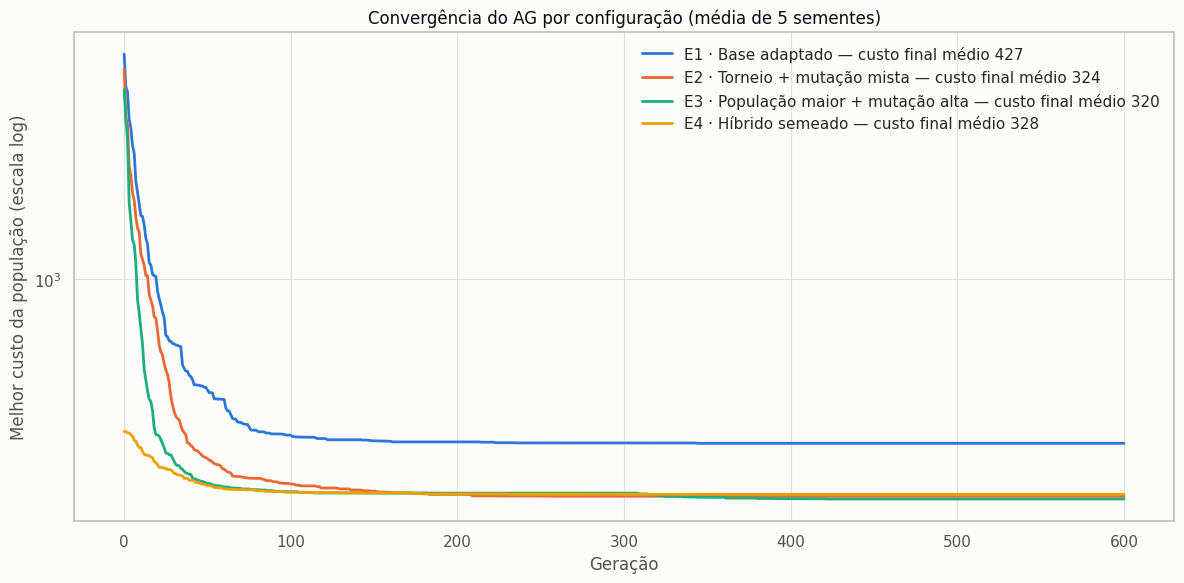

In [ ]:
# Convergência: média, entre sementes, do melhor custo de cada geração
fig, ax = plt.subplots(figsize=(12, 6))
for color, config in zip(SERIES_COLORS, GA_EXPERIMENTS):
    histories = np.array([run["best_history"] for run in experiment_runs if run["config"] == config.name])
    mean_curve = histories.mean(axis=0)
    ax.plot(mean_curve, color=color, label=f"{config.name} — custo final médio {mean_curve[-1]:.0f}")

ax.set_yscale("log")
ax.set_title("Convergência do AG por configuração (média de 5 sementes)")
ax.set_xlabel("Geração")
ax.set_ylabel("Melhor custo da população (escala log)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

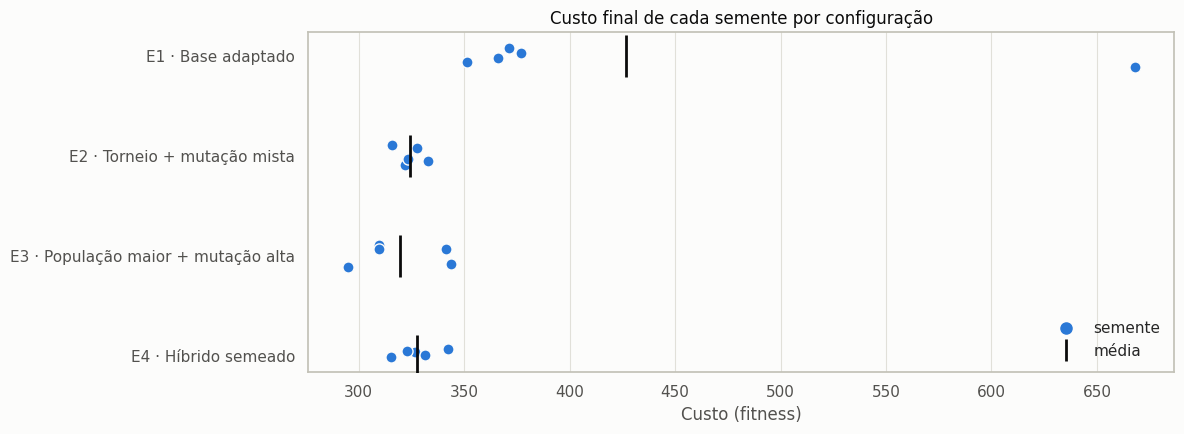

In [ ]:
# Dispersão do custo final entre sementes
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.stripplot(data=experiments_df, x="Custo", y="Experimento", color=HIGHLIGHT_COLOR, size=8,
              jitter=0.12, edgecolor=SURFACE_COLOR, linewidth=1, ax=ax)
means = experiments_df.groupby("Experimento", sort=False)["Custo"].mean()
ax.scatter(means.values, range(len(means)), marker="|", s=900, color=INK_COLOR, zorder=3)
ax.set_title("Custo final de cada semente por configuração")
ax.set_xlabel("Custo (fitness)")
ax.set_ylabel("")
ax.legend(handles=[
    Line2D([], [], marker="o", color=HIGHLIGHT_COLOR, linestyle="", markersize=8, label="semente"),
    Line2D([], [], marker="|", color=INK_COLOR, linestyle="", markersize=16, markeredgewidth=2, label="média"),
], frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## Melhor solução encontrada

A solução final é a de menor custo entre as 20 execuções. A seguir são registrados na comparação o melhor resultado do E1 (operadores do código base) e a melhor solução geral; depois vêm o resumo por veículo, a linha do tempo de cada entrega e a checagem explícita de todas as restrições.

In [ ]:
best_config_name = experiments_summary["custo_medio"].idxmin()
best_config = next(config for config in GA_EXPERIMENTS if config.name == best_config_name)
best_run = min(experiment_runs, key=lambda run: run["cost"])
base_run = min((run for run in experiment_runs if run["config"] == GA_EXPERIMENTS[0].name), key=lambda run: run["cost"])

print(f"Configuração com menor custo médio: {best_config_name}")
print(f"Melhor execução: {best_run['config']} (semente {best_run['seed']})\n")

base_ga_eval = record_result("AG · E1 base adaptado (melhor semente)", base_run["routes"], base_run["runtime_s"])
best_routes = best_run["routes"]
best_eval = record_result(f"AG · {best_run['config']}", best_routes, best_run["runtime_s"])

Configuração com menor custo médio: E3 · População maior + mutação alta
Melhor execução: E3 · População maior + mutação alta (semente 7)

📌 AG · E1 base adaptado (melhor semente)
Custo (fitness)     : 351.3
Distância total     : 220.7 km | tempo em rota: 15.2 h
Custo estimado      : R$ 1,209.02
Críticas no prazo   : 6/6 | alta no prazo: 100%
Violações           : 0 (carga +0 kg, autonomia +0.0 km, jornada +0 min, cadeia de frio 0)
--------------------------------------------------
📌 AG · E3 · População maior + mutação alta
Custo (fitness)     : 294.7
Distância total     : 168.1 km | tempo em rota: 13.0 h
Custo estimado      : R$ 1,002.81
Críticas no prazo   : 6/6 | alta no prazo: 100%
Violações           : 0 (carga +0 kg, autonomia +0.0 km, jornada +0 min, cadeia de frio 0)
--------------------------------------------------


In [ ]:
# Resumo por veículo
vehicle_summary = best_eval["vehicles"].merge(fleet[["vehicle_id", "model", "driver", "refrigerated"]], on="vehicle_id")
vehicle_summary["return_time"] = vehicle_summary["duration_min"].map(clock)
vehicle_summary["load_pct"] = vehicle_summary["load_kg"] / vehicle_summary["capacity_kg"]
vehicle_summary["autonomy_pct"] = vehicle_summary["distance_km"] / vehicle_summary["autonomy_km"]
vehicle_summary["shift_pct"] = vehicle_summary["duration_min"] / SHIFT_MIN

vehicle_summary[["vehicle_id", "driver", "refrigerated", "stops", "load_kg", "capacity_kg", "load_pct",
                 "distance_km", "autonomy_km", "autonomy_pct", "return_time", "shift_pct", "cost_rs"]].style.format({
    "load_kg": "{:.1f}", "load_pct": "{:.0%}", "distance_km": "{:.1f}", "autonomy_pct": "{:.0%}",
    "shift_pct": "{:.0%}", "cost_rs": "R$ {:.2f}",
})

,vehicle_id,driver,refrigerated,stops,load_kg,capacity_kg,load_pct,distance_km,autonomy_km,autonomy_pct,return_time,shift_pct,cost_rs
0,VAN-REF-01,Carlos Mendes,True,11,688.3,700,98%,62.4,120,52%,12:23,67%,R$ 439.39
1,VAN-02,Ana Ribeiro,False,8,504.0,900,56%,62.4,150,42%,11:35,57%,R$ 360.23
2,UTIL-REF-03,Bruno Tavares,True,5,334.6,350,96%,43.3,80,54%,09:59,37%,R$ 203.19


In [ ]:
# Linha do tempo das entregas (horários a partir da saída às 07:00)
schedule = best_eval["stops"].merge(
    nodes[["location_id", "name", "type", "neighborhood", "weight_kg", "refrigerated", "controlled"]],
    left_on="code", right_on="location_id"
)
schedule["arrival"] = schedule["arrival_min"].map(clock)
schedule["deadline"] = schedule["deadline_min"].map(clock)
schedule["on_time"] = np.where(schedule["slack_min"] >= 0, "✔", "✘")

schedule_view = schedule[["vehicle_id", "seq", "code", "name", "neighborhood", "priority", "refrigerated",
                          "controlled", "weight_kg", "arrival", "deadline", "slack_min", "on_time"]]
schedule_view.style.format({"weight_kg": "{:.1f}", "slack_min": "{:.0f}"}).background_gradient(
    subset=["slack_min"], cmap="Blues")

,vehicle_id,seq,code,name,neighborhood,priority,refrigerated,controlled,weight_kg,arrival,deadline,slack_min,on_time
0,VAN-REF-01,1,H01,Hospital Universitário - Unidade Central,Cerqueira César,critica,False,True,199.4,07:12,09:00,108,✔
1,VAN-REF-01,2,D03,Paciente domiciliar 03,Aclimação,critica,True,False,34.0,07:47,09:00,73,✔
2,VAN-REF-01,3,H07,Centro Oncológico Vila Mariana,Vila Mariana,critica,True,True,92.0,08:07,09:00,52,✔
3,VAN-REF-01,4,D02,Paciente domiciliar 02,Vila Mariana,alta,True,False,8.5,08:30,12:00,209,✔
4,VAN-REF-01,5,D01,Paciente domiciliar 01,Moema,alta,True,False,29.5,08:53,12:00,187,✔
5,VAN-REF-01,6,U06,UBS Saúde,Saúde,regular,False,False,26.4,09:18,15:00,342,✔
6,VAN-REF-01,7,U05,UBS Jabaquara,Jabaquara,alta,True,False,45.0,09:40,12:00,140,✔
7,VAN-REF-01,8,H04,Hospital Regional Santo Amaro,Santo Amaro,alta,False,True,210.6,10:14,12:00,105,✔
8,VAN-REF-01,9,D11,Paciente domiciliar 11,Campo Limpo,regular,False,False,6.0,10:51,15:00,248,✔
9,VAN-REF-01,10,U16,UBS Morumbi,Morumbi,alta,True,False,26.9,11:28,12:00,32,✔


In [ ]:
# Checagem explícita das restrições na solução final
critical_stops = schedule[schedule["priority"] == "critica"]
checks = {
    "Carga dentro da capacidade em todos os veículos": best_eval["capacity_excess_kg"] == 0,
    "Distância dentro da autonomia em todos os veículos": best_eval["autonomy_excess_km"] == 0,
    "Retorno ao CD dentro da jornada de 8 h": best_eval["shift_excess_min"] == 0,
    "Entregas refrigeradas apenas em veículos refrigerados": best_eval["cold_violations"] == 0,
    f"Entregas críticas no prazo ({(critical_stops['slack_min'] >= 0).sum()}/{len(critical_stops)})":
        best_eval["critical_late"] == 0,
    f"Entregas de alta prioridade no prazo ({best_eval['high_on_time']:.0%})": best_eval["high_on_time"] == 1.0,
    "Todas as entregas atendidas exatamente uma vez":
        sorted(schedule["node"]) == list(range(1, problem.n)),
}
for description, passed in checks.items():
    print(f"{'✔' if passed else '✘'} {description}")
print(f"\nFolga mínima entre as críticas: {critical_stops['slack_min'].min():.0f} min")

✔ Carga dentro da capacidade em todos os veículos
✔ Distância dentro da autonomia em todos os veículos
✔ Retorno ao CD dentro da jornada de 8 h
✔ Entregas refrigeradas apenas em veículos refrigerados
✔ Entregas críticas no prazo (6/6)
✔ Entregas de alta prioridade no prazo (100%)
✔ Todas as entregas atendidas exatamente uma vez

Folga mínima entre as críticas: 25 min


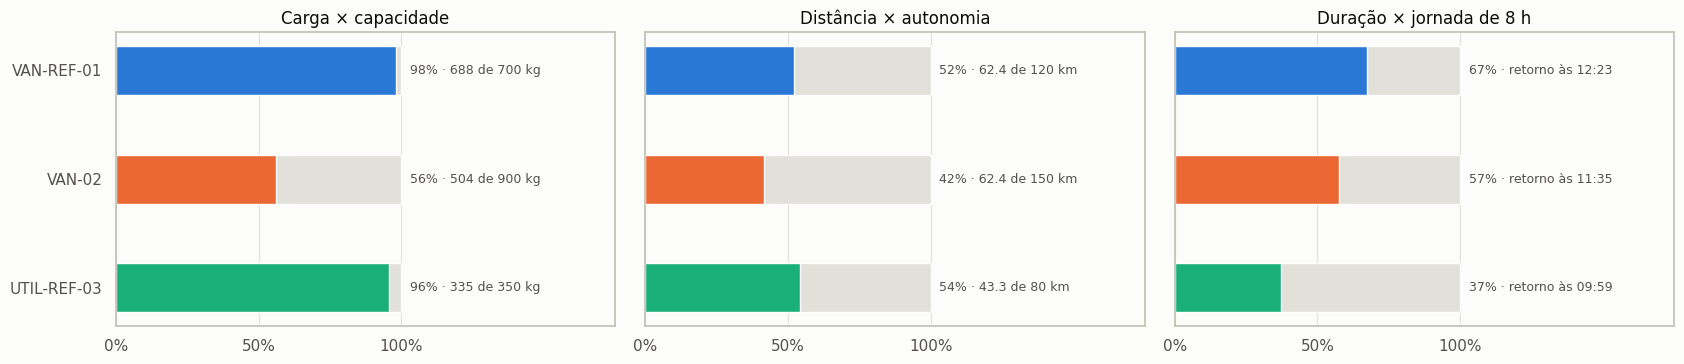

In [ ]:
# Uso da frota: carga, autonomia e jornada de cada veículo
VEHICLE_COLORS = dict(zip(problem.vehicle_ids, SERIES_COLORS))
usage_panels = [
    ("Carga × capacidade", "load_pct", lambda row: f"{row.load_kg:.0f} de {row.capacity_kg} kg"),
    ("Distância × autonomia", "autonomy_pct", lambda row: f"{row.distance_km:.1f} de {row.autonomy_km} km"),
    ("Duração × jornada de 8 h", "shift_pct", lambda row: f"retorno às {row.return_time}"),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8), sharey=True)
for ax, (title, column, label) in zip(axes, usage_panels):
    for y, row in enumerate(vehicle_summary.itertuples()):
        ax.barh(y, 1.0, height=0.45, color=GRID_COLOR)
        ax.barh(y, getattr(row, column), height=0.45, color=VEHICLE_COLORS[row.vehicle_id])
        ax.text(1.03, y, f"{getattr(row, column):.0%} · {label(row)}", va="center", color=INK_SECONDARY, fontsize=9)
    ax.set_title(title)
    ax.set_xlim(0, 1.75)
    ax.set_xticks([0, 0.5, 1.0], ["0%", "50%", "100%"])
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(vehicle_summary)), vehicle_summary["vehicle_id"])
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

## Comparação final das abordagens

A tabela reúne todas as abordagens registradas em `results`, ordenadas pelo custo. Os gráficos destacam o AG final e cinzam as demais; abordagens com qualquer violação de restrição estão marcadas como inviáveis. Distância e custo estimado em R$ mostram o ganho operacional; o percentual de críticas no prazo mostra o ganho em nível de serviço — e por que a menor distância, sozinha, não é o objetivo certo.

In [ ]:
comparison_df = pd.DataFrame(results).sort_values("Custo (fitness)").reset_index(drop=True)
comparison_df.index += 1

comparison_df.style.background_gradient(
    subset=["Custo (fitness)", "Distância (km)", "Custo estimado (R$)"], cmap="Greens_r"
).background_gradient(
    subset=["Críticas no prazo", "Alta no prazo"], cmap="Greens"
).format({"Custo (fitness)": "{:,.1f}", "Distância (km)": "{:.1f}", "Tempo em rota (h)": "{:.1f}",
          "Custo estimado (R$)": "R$ {:,.2f}", "Críticas no prazo": "{:.0%}", "Alta no prazo": "{:.0%}",
          "Tempo de execução (s)": "{:.2f}"})

,Abordagem,Custo (fitness),Distância (km),Tempo em rota (h),Custo estimado (R$),Veículos,Críticas no prazo,Alta no prazo,Violações,Tempo de execução (s)
1,AG · E3 · População maior + mutação alta,294.7,168.1,13.0,"R$ 1,002.81",3,100%,100%,0,5.41
2,AG · E1 base adaptado (melhor semente),351.3,220.7,15.2,"R$ 1,209.02",3,100%,100%,0,1.23
3,Despacho por prioridade,453.5,226.9,15.4,"R$ 1,291.59",2,83%,91%,0,0.00
4,Vizinho mais próximo,974.9,229.6,15.5,"R$ 1,273.75",3,50%,91%,0,0.00
5,Aleatória (melhor de 1.000),"2,197.1",325.9,19.6,"R$ 1,599.86",3,67%,82%,5,0.03
6,Vizinho mais próximo + 2-opt,"2,654.2",191.1,13.9,"R$ 1,118.37",3,17%,73%,0,0.00
7,TSP do código base (só VAN-02),"9,849.7",156.5,12.5,R$ 961.48,1,17%,36%,13,7.27


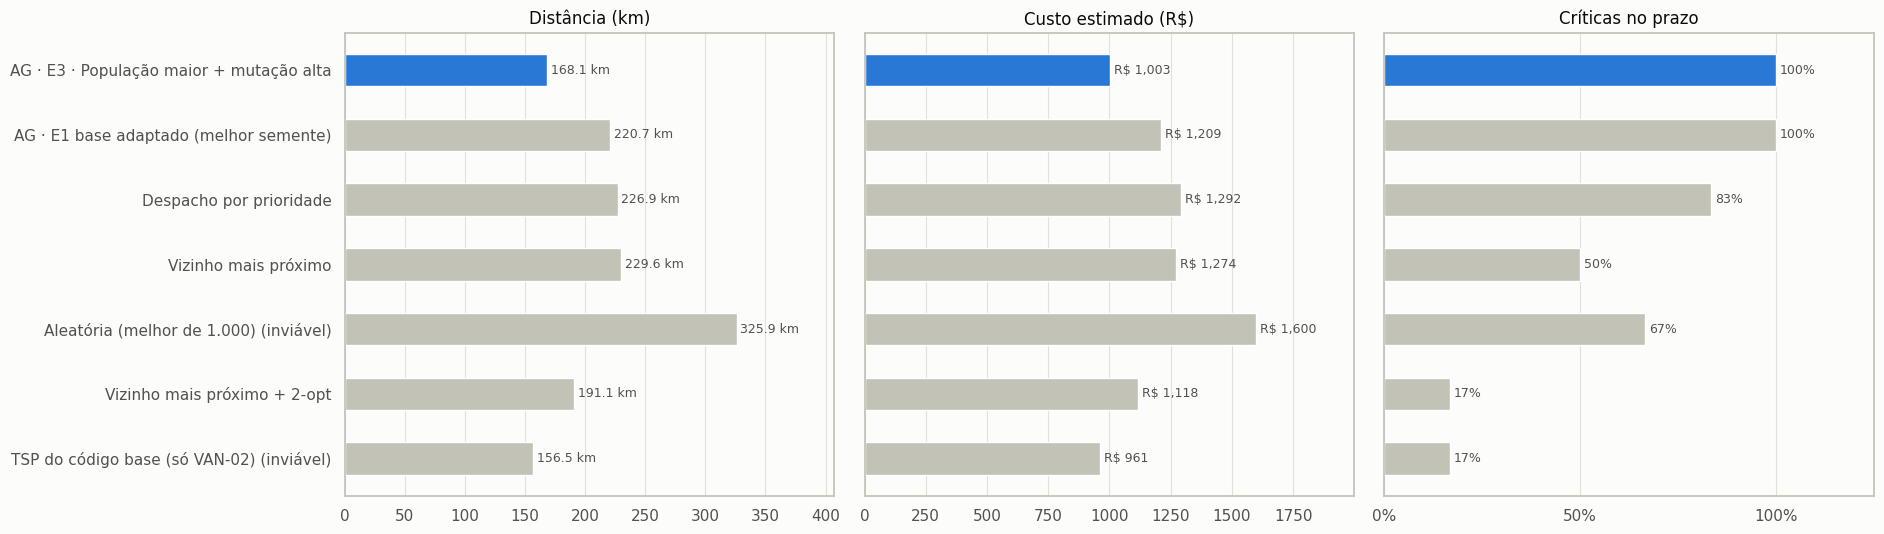

In [ ]:
# Distância, custo estimado e pontualidade por abordagem (AG final em destaque)
best_name = f"AG · {best_run['config']}"
chart_df = comparison_df.assign(
    Rótulo=[name + ("" if violations == 0 else " (inviável)")
            for name, violations in zip(comparison_df["Abordagem"], comparison_df["Violações"])]
)
panels = [("Distância (km)", "{:.1f} km"), ("Custo estimado (R$)", "R$ {:,.0f}"), ("Críticas no prazo", "{:.0%}")]

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), sharey=True)
for ax, (metric, fmt) in zip(axes, panels):
    colors = [HIGHLIGHT_COLOR if name == best_name else MUTED_COLOR for name in chart_df["Abordagem"]]
    ax.barh(chart_df["Rótulo"], chart_df[metric], height=0.5, color=colors)
    for y, value in enumerate(chart_df[metric]):
        ax.text(value + chart_df[metric].max() * 0.01, y, fmt.format(value), va="center", color=INK_SECONDARY, fontsize=9)
    ax.set_title(metric)
    ax.set_xlim(0, chart_df[metric].max() * 1.25)
    ax.grid(axis="y", visible=False)
axes[2].set_xticks([0, 0.5, 1.0], ["0%", "50%", "100%"])
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
# Ganho do AG final em relação às heurísticas
for name, reference in [("Vizinho mais próximo", nn_eval), ("Despacho por prioridade", priority_eval),
                        ("Vizinho mais próximo + 2-opt", nn_2opt_eval)]:
    saved_km = reference["distance_km"] - best_eval["distance_km"]
    saved_rs = reference["cost_rs"] - best_eval["cost_rs"]
    print(f"vs {name:<29}: economia de {saved_km:5.1f} km ({saved_km / reference['distance_km']:.1%}) e "
          f"R$ {saved_rs:6.2f} | críticas no prazo {reference['critical_on_time']:.0%} → {best_eval['critical_on_time']:.0%}")

vs Vizinho mais próximo         : economia de  61.4 km (26.8%) e R$ 270.94 | críticas no prazo 50% → 100%
vs Despacho por prioridade      : economia de  58.8 km (25.9%) e R$ 288.78 | críticas no prazo 83% → 100%
vs Vizinho mais próximo + 2-opt : economia de  22.9 km (12.0%) e R$ 115.56 | críticas no prazo 17% → 100%


## Visualização das rotas otimizadas

O mapa estático mostra as três rotas com a ordem de visita; losangos indicam entregas críticas. O mapa interativo (Folium/Leaflet, base OpenStreetMap) permite ligar e desligar cada veículo na legenda e consultar, ao clicar em uma parada, prioridade, horário previsto, prazo, peso e necessidade de refrigeração. As linhas ligam as paradas em sequência; a distância percorrida nas ruas é a estimada pelo fator de tortuosidade. O mapa também é salvo em `fase2_mapa_rotas.html` para abrir no navegador.

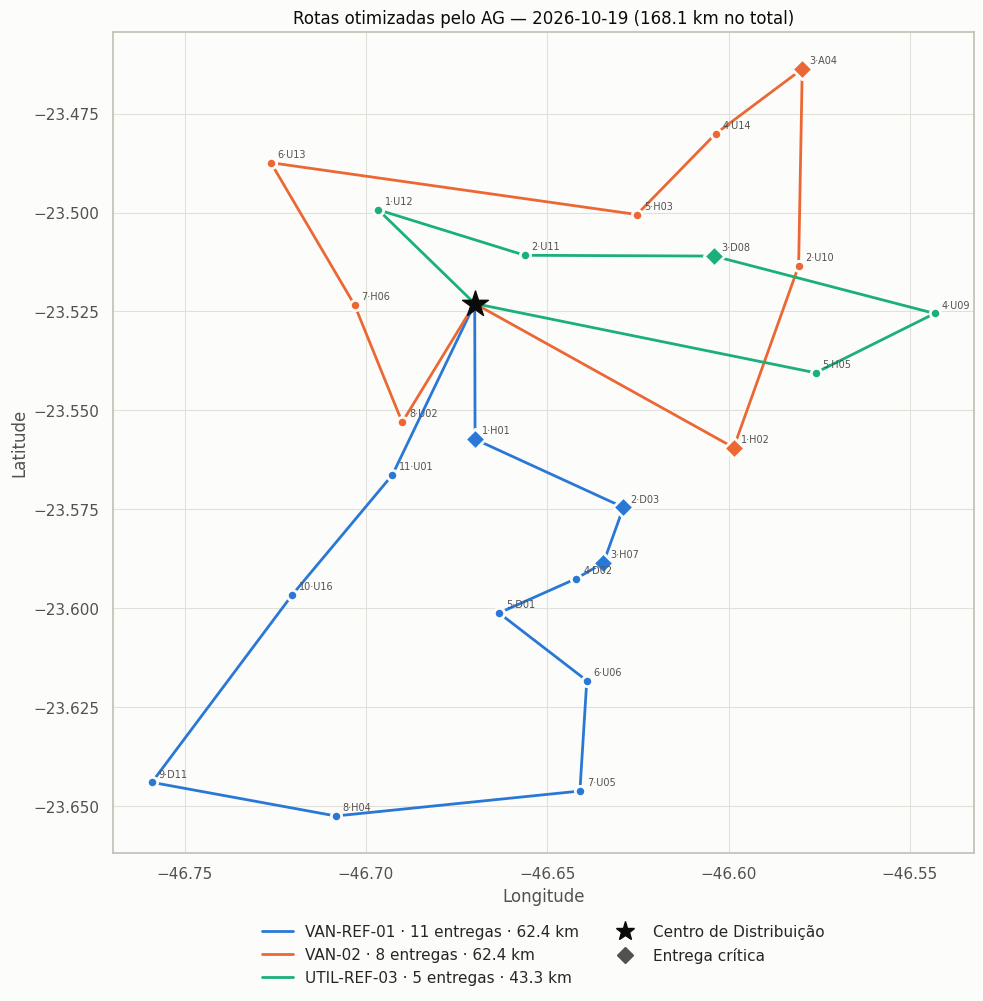

In [ ]:
# Mapa estático das rotas
fig, ax = plt.subplots(figsize=(10, 10))
for k, route in enumerate(best_routes):
    vehicle_id = problem.vehicle_ids[k]
    color = VEHICLE_COLORS[vehicle_id]
    tour = [0, *route, 0]
    route_km = vehicle_summary.loc[k, "distance_km"]
    ax.plot(nodes.loc[tour, "longitude"], nodes.loc[tour, "latitude"], color=color, linewidth=2, zorder=2,
            label=f"{vehicle_id} · {len(route)} entregas · {route_km:.1f} km")
    for seq, node in enumerate(route, start=1):
        critical = problem.priority[node] == "critica"
        ax.scatter(nodes.loc[node, "longitude"], nodes.loc[node, "latitude"], s=110 if critical else 55,
                   marker="D" if critical else "o", color=color, edgecolor=SURFACE_COLOR, linewidth=2, zorder=3)
        ax.annotate(f"{seq}·{problem.codes[node]}", (nodes.loc[node, "longitude"], nodes.loc[node, "latitude"]),
                    xytext=(5, 4), textcoords="offset points", fontsize=7, color=INK_SECONDARY)
ax.scatter(nodes.loc[0, "longitude"], nodes.loc[0, "latitude"], s=380, marker="*", color=INK_COLOR, zorder=4)

handles, _ = ax.get_legend_handles_labels()
handles += [
    Line2D([], [], marker="*", color=INK_COLOR, linestyle="", markersize=14, label="Centro de Distribuição"),
    Line2D([], [], marker="D", color=INK_SECONDARY, linestyle="", markersize=8, label="Entrega crítica"),
]
ax.legend(handles=handles, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2)
ax.set_aspect(1 / np.cos(np.radians(nodes["latitude"].mean())))
ax.set_title(f"Rotas otimizadas pelo AG — {ANALYSIS_DAY} ({best_eval['distance_km']:.1f} km no total)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="folium")

def relative_luminance(hex_color):
    channels = [int(hex_color[i:i + 2], 16) / 255 for i in (1, 3, 5)]
    linear = [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in channels]
    return 0.2126 * linear[0] + 0.7152 * linear[1] + 0.0722 * linear[2]


def label_ink(fill_hex):
    """Tinta do número dentro do marcador: branca ou preta, a de maior contraste com o preenchimento."""
    fill = relative_luminance(fill_hex)
    white_contrast = 1.05 / (fill + 0.05)
    ink_contrast = (fill + 0.05) / (relative_luminance(INK_COLOR) + 0.05)
    return "#ffffff" if white_contrast >= ink_contrast else INK_COLOR


# Alterado para cartodbpositron para contornar o bloqueio do OpenStreetMap no Colab
route_map = folium.Map(location=[nodes["latitude"].mean(), nodes["longitude"].mean()], zoom_start=11,
                       tiles="cartodbpositron")

for k, route in enumerate(best_routes):
    row = vehicle_summary.loc[k]
    color = VEHICLE_COLORS[row.vehicle_id]
    group = folium.FeatureGroup(
        name=(f'<span style="color:{color}">&#9632;</span> {row.vehicle_id} · {row.driver} '
              f'({len(route)} entregas, {row.distance_km:.1f} km)')
    )
    folium.PolyLine([(nodes.loc[node, "latitude"], nodes.loc[node, "longitude"]) for node in [0, *route, 0]],
                    color=color, weight=4, opacity=0.85,
                    tooltip=f"{row.vehicle_id}: {row.distance_km:.1f} km, retorno às {row.return_time}").add_to(group)
    for stop in schedule[schedule["vehicle_id"] == row.vehicle_id].itertuples():
        ring = INK_COLOR if stop.priority == "critica" else SURFACE_COLOR
        icon_html = (f'<div style="background:{color};color:{label_ink(color)};border:2px solid {ring};'
                     f'border-radius:50%;width:24px;height:24px;line-height:20px;text-align:center;'
                     f'font:600 11px system-ui,sans-serif;box-sizing:border-box;">{stop.seq}</div>')
        popup_html = (f"<b>[{stop.code}] {stop.name}</b><br>{stop.type} · {stop.neighborhood}<br>"
                      f"Prioridade: {stop.priority}<br>Chegada: {stop.arrival} (prazo {stop.deadline})<br>"
                      f"Peso: {stop.weight_kg:.1f} kg" + ("<br>Refrigerado (2 a 8 °C)" if stop.refrigerated else "")
                      + ("<br>Controlado: exige assinatura" if stop.controlled else ""))
        folium.Marker([nodes.loc[stop.node, "latitude"], nodes.loc[stop.node, "longitude"]],
                      icon=folium.DivIcon(html=icon_html, icon_size=(24, 24), icon_anchor=(12, 12)),
                      tooltip=f"{stop.seq}. [{stop.code}] {stop.name} — {stop.arrival}",
                      popup=folium.Popup(popup_html, max_width=300)).add_to(group)
    group.add_to(route_map)

folium.Marker([nodes.loc[0, "latitude"], nodes.loc[0, "longitude"]], tooltip=nodes.loc[0, "name"],
              icon=folium.Icon(color="black", icon="home")).add_to(route_map)
route_map.get_root().html.add_child(folium.Element(
    '<div style="position:fixed;bottom:24px;left:24px;z-index:9999;background:#fcfcfb;padding:8px 12px;'
    'border:1px solid #e1e0d9;border-radius:6px;font:12px system-ui,sans-serif;color:#52514e;">'
    'Número = ordem de visita · contorno escuro = entrega crítica</div>'
))
route_map.fit_bounds([[nodes["latitude"].min(), nodes["longitude"].min()],
                      [nodes["latitude"].max(), nodes["longitude"].max()]], padding=(20, 20))
folium.LayerControl(collapsed=False).add_to(route_map)

map_path = Path("fase2_mapa_rotas.html")
route_map.save(map_path)
print(f"Mapa interativo salvo em {map_path.resolve()}")

# Renderiza o mapa usando a exibição nativa
display(route_map)


Mapa interativo salvo em /content/fase2_mapa_rotas.html


## Simulação da semana: eficiência diária

Para gerar relatórios diários e semanais, os cinco dias de pedidos são roteados pela configuração de menor custo médio (semente 42) e pelo vizinho mais próximo, tratado como o método atual da central. Para o dia analisado acima é reaproveitada a melhor solução dos experimentos. Os indicadores por dia — distância, horas em rota, custo estimado e pontualidade — alimentam os relatórios gerados pela LLM.

In [ ]:
weekly_rows, weekly_solutions = [], {}
for day, weekday in WEEKDAY_BY_DATE.items():
    day_problem = RoutingProblem(build_day_nodes(day), fleet)
    day_heuristics = heuristic_solutions(day_problem)
    if day == ANALYSIS_DAY:
        ga_routes, ga_runtime = best_routes, best_run["runtime_s"]
    else:
        day_run = run_ga(day_problem, best_config, SEED, heuristic_routes=list(day_heuristics.values()))
        ga_routes, ga_runtime = day_run["routes"], day_run["runtime_s"]
    ga = evaluate_solution(day_problem, ga_routes)
    nn = evaluate_solution(day_problem, day_heuristics["nearest"])
    weekly_solutions[day] = {"problem": day_problem, "routes": ga_routes, "eval": ga}
    weekly_rows.append({
        "date": day, "weekday": weekday,
        "deliveries": day_problem.n - 1, "weight_kg": sum(day_problem.demand),
        "critical": ga["critical_total"], "refrigerated": int(sum(day_problem.cold)),
        "ga_km": ga["distance_km"], "nn_km": nn["distance_km"],
        "ga_hours": ga["duration_h"], "nn_hours": nn["duration_h"],
        "ga_cost_rs": ga["cost_rs"], "nn_cost_rs": nn["cost_rs"],
        "ga_critical_on_time": ga["critical_on_time"], "nn_critical_on_time": nn["critical_on_time"],
        "ga_high_on_time": ga["high_on_time"], "nn_high_on_time": nn["high_on_time"],
        "ga_feasible": ga["feasible"], "ga_runtime_s": ga_runtime,
    })

weekly_df = pd.DataFrame(weekly_rows)
weekly_df["saved_km"] = weekly_df["nn_km"] - weekly_df["ga_km"]
weekly_df["saved_pct"] = weekly_df["saved_km"] / weekly_df["nn_km"]
weekly_df["saved_hours"] = weekly_df["nn_hours"] - weekly_df["ga_hours"]
weekly_df["saved_rs"] = weekly_df["nn_cost_rs"] - weekly_df["ga_cost_rs"]

weekly_df.style.format({
    "weight_kg": "{:.1f}", "ga_km": "{:.1f}", "nn_km": "{:.1f}", "ga_hours": "{:.1f}", "nn_hours": "{:.1f}",
    "ga_cost_rs": "R$ {:,.2f}", "nn_cost_rs": "R$ {:,.2f}", "ga_critical_on_time": "{:.0%}",
    "nn_critical_on_time": "{:.0%}", "ga_high_on_time": "{:.0%}", "nn_high_on_time": "{:.0%}",
    "ga_runtime_s": "{:.1f}", "saved_km": "{:.1f}", "saved_pct": "{:.1%}", "saved_hours": "{:.1f}",
    "saved_rs": "R$ {:,.2f}",
})

,date,weekday,deliveries,weight_kg,critical,refrigerated,ga_km,nn_km,ga_hours,nn_hours,ga_cost_rs,nn_cost_rs,ga_critical_on_time,nn_critical_on_time,ga_high_on_time,nn_high_on_time,ga_feasible,ga_runtime_s,saved_km,saved_pct,saved_hours,saved_rs
0,2026-10-19,segunda-feira,24,1526.9,6,10,168.1,229.6,13.0,15.5,"R$ 1,002.81","R$ 1,273.75",100%,50%,100%,91%,True,5.4,61.4,26.8%,2.6,R$ 270.94
1,2026-10-20,terça-feira,26,1420.7,6,11,173.7,215.9,13.7,15.4,"R$ 1,034.08","R$ 1,275.79",100%,67%,100%,92%,True,6.1,42.2,19.6%,1.8,R$ 241.70
2,2026-10-21,quarta-feira,21,1205.5,5,12,163.6,175.3,12.0,12.5,R$ 916.45,"R$ 1,032.34",100%,20%,100%,82%,True,6.6,11.7,6.7%,0.5,R$ 115.90
3,2026-10-22,quinta-feira,21,1348.4,3,14,164.2,201.1,12.1,13.7,R$ 939.47,"R$ 1,084.52",100%,33%,100%,100%,True,5.2,36.9,18.4%,1.5,R$ 145.05
4,2026-10-23,sexta-feira,20,1050.6,5,9,148.2,163.3,11.2,11.8,R$ 847.15,R$ 962.78,100%,20%,100%,100%,True,7.1,15.1,9.3%,0.6,R$ 115.63


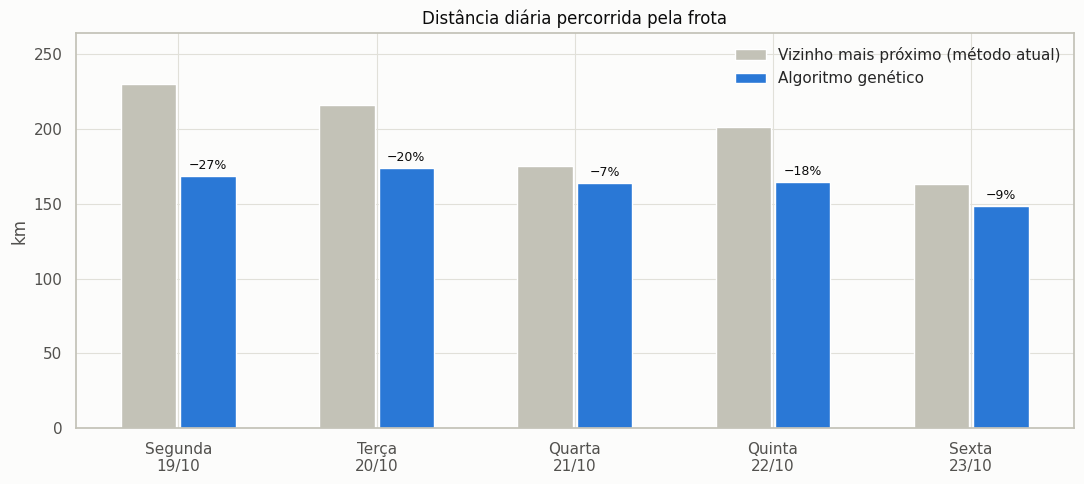

Semana: 167.4 km (17.0%), 7.0 h e R$ 889.22 economizados em relação ao método atual


In [ ]:
# Distância diária: AG × método atual
week_labels = [f"{weekday.split('-')[0].capitalize()}\n{day[8:]}/{day[5:7]}"
               for day, weekday in zip(weekly_df["date"], weekly_df["weekday"])]
x = np.arange(len(weekly_df))

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - 0.15, weekly_df["nn_km"], width=0.28, color=MUTED_COLOR, label="Vizinho mais próximo (método atual)")
ax.bar(x + 0.15, weekly_df["ga_km"], width=0.28, color=HIGHLIGHT_COLOR, label="Algoritmo genético")
for xi, (ga_km, pct) in enumerate(zip(weekly_df["ga_km"], weekly_df["saved_pct"])):
    ax.text(xi + 0.15, ga_km + 3, f"−{pct:.0%}", ha="center", va="bottom", color=INK_COLOR, fontsize=9)
ax.set_xticks(x, week_labels)
ax.set_title("Distância diária percorrida pela frota")
ax.set_ylabel("km")
ax.set_ylim(0, weekly_df["nn_km"].max() * 1.15)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

week_totals = weekly_df[["deliveries", "weight_kg", "ga_km", "nn_km", "saved_km", "ga_hours", "nn_hours",
                         "saved_hours", "ga_cost_rs", "nn_cost_rs", "saved_rs"]].sum()
print(f"Semana: {week_totals['saved_km']:.1f} km ({week_totals['saved_km'] / week_totals['nn_km']:.1%}), "
      f"{week_totals['saved_hours']:.1f} h e R$ {week_totals['saved_rs']:,.2f} economizados em relação ao método atual")

In [ ]:
# Padrões da semana usados para sugerir melhorias
week_vehicles = pd.concat([
    solution["eval"]["vehicles"].assign(date=day) for day, solution in weekly_solutions.items()
])
week_vehicles["load_pct"] = week_vehicles["load_kg"] / week_vehicles["capacity_kg"]
week_vehicles["autonomy_pct"] = week_vehicles["distance_km"] / week_vehicles["autonomy_km"]
week_vehicles["shift_pct"] = week_vehicles["duration_min"] / SHIFT_MIN
vehicle_patterns = week_vehicles.groupby("vehicle_id").agg(
    carga_media=("load_pct", "mean"), carga_maxima=("load_pct", "max"),
    autonomia_media=("autonomy_pct", "mean"), autonomia_maxima=("autonomy_pct", "max"),
    jornada_media=("shift_pct", "mean"), entregas_por_dia=("stops", "mean"),
).loc[problem.vehicle_ids]

week_stops = pd.concat([solution["eval"]["stops"].assign(date=day) for day, solution in weekly_solutions.items()])
critical_week = week_stops[week_stops["priority"] == "critica"]
zone_by_day = deliveries.pivot_table(index="zone", columns="date", values="location_id", aggfunc="count", fill_value=0)

print("Uso médio da frota na semana:")
display(vehicle_patterns.style.format("{:.0%}", subset=vehicle_patterns.columns[:-1]).format(
    "{:.1f}", subset=["entregas_por_dia"]))
print(f"Entregas refrigeradas: {weekly_df['refrigerated'].sum()} de {weekly_df['deliveries'].sum()} "
      f"({weekly_df['refrigerated'].sum() / weekly_df['deliveries'].sum():.0%})")
print(f"Folga das entregas críticas: mínima {critical_week['slack_min'].min():.0f} min, "
      f"mediana {critical_week['slack_min'].median():.0f} min")
zone_by_day

Uso médio da frota na semana:


,carga_media,carga_maxima,autonomia_media,autonomia_maxima,jornada_media,entregas_por_dia
vehicle_id,,,,,,
VAN-REF-01,80%,98%,49%,53%,59%,9.4
VAN-02,49%,56%,32%,42%,46%,6.2
UTIL-REF-03,90%,97%,72%,86%,50%,6.8


Entregas refrigeradas: 56 de 112 (50%)
Folga das entregas críticas: mínima 18 min, mediana 63 min


date,2026-10-19,2026-10-20,2026-10-21,2026-10-22,2026-10-23
zone,,,,,
Centro,1,2,1,2,0
Leste,3,6,4,3,3
Norte,8,8,4,3,5
Oeste,5,4,6,5,5
Sul,7,6,6,8,7


## Integração com LLM: instruções, relatórios e perguntas em linguagem natural

```text
pedidos + frota ──► AG (VRP) ──► rotas e indicadores ──► contexto JSON ──► LLM ──► instruções / relatórios / respostas
                                          ▲                                            │
                                          └────────── verificação automática ◄─────────┘
```

A LLM utilizada é o **Google Gemini** (especificamente `gemini-3.8-flash`), acessado pelo SDK `google.generativeai`. A credencial é lida do ambiente ou dos segredos do Colab (`GOOGLE_API_KEY`). Sem credencial, ou com a variável `LLM_MODE=offline`, o notebook usa geradores determinísticos por template: todas as células executam e os resultados continuam reproduzíveis, apenas sem a redação da LLM.

Técnicas de prompt engineering aplicadas:

1. **Papel e público explícitos**: o system prompt (via `system_instruction`) define o assistente de logística hospitalar; cada tarefa declara o leitor (motorista, coordenação, gestão).
2. **Contexto estruturado e delimitado**: rotas, indicadores e padrões da semana vão em JSON dentro de `<dados_operacao>`, separados das instruções.
3. **Ancoragem nos dados**: a LLM só pode usar o que está no contexto e deve dizer quando algo não consta, o que reduz alucinação de horários, endereços e números.
4. **Formato de saída especificado**: seções, tabelas e a citação de cada parada pelo código (`[U05]`), o que torna a resposta verificável por código.
5. **Regras do domínio**: cadeia de frio (2 °C a 8 °C), medicamentos controlados e privacidade de pacientes domiciliares.

Uma execução completa faz diversas chamadas. Cada chamada registra modelo, tokens e tempo em `llm_log` (monitoramento). As respostas passam por verificações automáticas: cobertura das paradas nas instruções, fidelidade dos números nos relatórios e acerto em perguntas com resposta conhecida.

In [ ]:
!pip install -q google-generativeai
print("Pacote google-generativeai instalado com sucesso!")

Pacote google-generativeai instalado com sucesso!


In [ ]:
import google.generativeai as genai
import os

# Garante que a API key está configurada antes de chamar a lista
genai.configure(api_key=os.environ.get("GOOGLE_API_KEY"))

print("Modelos disponíveis que suportam 'generateContent':")
for m in genai.list_models():
    if 'generateContent' in m.supported_generation_methods:
        print(f" - {m.name}")


Modelos disponíveis que suportam 'generateContent':
 - models/gemini-2.5-flash
 - models/gemini-2.5-pro
 - models/gemini-2.5-flash-preview-tts
 - models/gemini-2.5-pro-preview-tts
 - models/gemma-4-26b-a4b-it
 - models/gemma-4-31b-it
 - models/gemini-flash-latest
 - models/gemini-flash-lite-latest
 - models/gemini-pro-latest
 - models/gemini-2.5-flash-lite
 - models/gemini-2.5-flash-image
 - models/gemini-3-flash-preview
 - models/gemini-3.1-pro-preview
 - models/gemini-3.1-pro-preview-customtools
 - models/gemini-3.1-flash-lite-preview
 - models/gemini-3.1-flash-lite
 - models/gemini-3-pro-image-preview
 - models/gemini-3-pro-image
 - models/nano-banana-pro-preview
 - models/gemini-3.1-flash-image-preview
 - models/gemini-3.1-flash-image
 - models/gemini-3.1-flash-lite-image
 - models/gemini-nano-banana-2.1
 - models/gemini-3.5-flash
 - models/gemini-3.5-flash-lite
 - models/gemini-omni-flash-preview
 - models/gemini-omni-1.1-flash
 - models/gemini-3.5-transcribe
 - models/gemini-3.6-

/tmp/ipykernel_21792/2219379184.py:1: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  import google.generativeai as genai


In [ ]:
# Configuração da LLM (Google Gemini)
LLM_MODEL = "gemini-3.8-flash"
LLM_MODE = os.getenv("LLM_MODE", "auto").lower()

try:
    import google.generativeai as genai
except ImportError:
    genai = None

def create_llm_client():
    """Devolve (configurado, descrição do modo)."""
    if LLM_MODE == "offline":
        return False, "offline (LLM_MODE=offline)"
    if genai is None:
        return False, "offline (pacote google-generativeai não instalado. Rode: pip install google-generativeai)"

    api_key = os.environ.get("GOOGLE_API_KEY")
    if not api_key:
        return False, "offline (defina GOOGLE_API_KEY para usar a LLM)"

    try:
        genai.configure(api_key=api_key)
        return True, f"online ({LLM_MODEL})"
    except Exception as exc:
        return False, f"offline (erro ao configurar: {exc})"

llm_client_ready, llm_status = create_llm_client()
print("Modo da LLM:", llm_status)


Modo da LLM: online (gemini-3.8-flash)


In [ ]:
def items_by_stop(day):
    """Itens de cada entrega do dia, no formato 'item × quantidade'."""
    day_orders = orders[orders["date"] == day]
    return {location_id: [f"{row.item} × {row.quantity}" for row in group.itertuples()]
            for location_id, group in day_orders.groupby("location_id")}


def pct(value):
    return f"{value:.0%}"


def build_operation_context():
    """Contexto da LLM: rotas do dia, comparação com o método atual, semana e padrões (JSON)."""
    day_items = items_by_stop(ANALYSIS_DAY)
    routes_context = []
    for k, route in enumerate(best_routes):
        row = vehicle_summary.loc[k]
        stops = schedule[schedule["vehicle_id"] == row.vehicle_id]
        routes_context.append({
            "veiculo": row.vehicle_id, "modelo": row.model, "motorista": row.driver,
            "refrigerado": bool(row.refrigerated),
            "capacidade_kg": int(row.capacity_kg), "carga_kg": round(row.load_kg, 1), "ocupacao_carga": pct(row.load_pct),
            "autonomia_km": int(row.autonomy_km), "distancia_km": round(row.distance_km, 1),
            "uso_autonomia": pct(row.autonomy_pct),
            "saida": DEPARTURE_TIME, "retorno_previsto": row.return_time, "duracao_h": round(row.duration_min / 60, 1),
            "custo_estimado_rs": round(row.cost_rs, 2),
            "paradas": [{
                "ordem": int(stop.seq), "codigo": stop.code, "local": stop.name, "tipo": stop.type,
                "bairro": stop.neighborhood, "prioridade": stop.priority,
                "chegada": stop.arrival, "prazo": stop.deadline, "folga_min": int(round(stop.slack_min)),
                "peso_kg": round(stop.weight_kg, 1), "refrigerado": bool(stop.refrigerated),
                "controlado": bool(stop.controlled), "itens": day_items[stop.code],
            } for stop in stops.itertuples()],
        })

    return {
        "data": f"{ANALYSIS_DAY} ({WEEKDAY_BY_DATE[ANALYSIS_DAY]})",
        "saida_do_cd": DEPARTURE_TIME,
        "centro_de_distribuicao": {"codigo": "CD", "nome": nodes.loc[0, "name"], "bairro": nodes.loc[0, "neighborhood"]},
        "regras_operacionais": {
            "velocidade_media_kmh": AVG_SPEED_KMH,
            "jornada_maxima_h": SHIFT_MIN / 60,
            "prazo_por_prioridade": {priority: clock(minutes) for priority, minutes in PRIORITY_DEADLINE_MIN.items()},
            "cadeia_de_frio": "itens refrigerados entre 2 °C e 8 °C, transportados apenas em veículos refrigerados",
            "controlados": "medicamentos controlados exigem conferência e assinatura do responsável no recebimento",
        },
        "indicadores_do_dia": {
            "entregas": problem.n - 1, "peso_total_kg": round(sum(problem.demand), 1),
            "distancia_total_km": round(best_eval["distance_km"], 1),
            "tempo_total_em_rota_h": round(best_eval["duration_h"], 1),
            "custo_estimado_rs": round(best_eval["cost_rs"], 2),
            "entregas_criticas_no_prazo": f"{best_eval['critical_total'] - best_eval['critical_late']}/{best_eval['critical_total']}",
            "entregas_alta_no_prazo": pct(best_eval["high_on_time"]),
            "violacoes_de_restricoes": best_eval["violations"],
            "algoritmo": f"algoritmo genético, {best_run['config']}",
        },
        "comparacao_metodo_atual": {
            "metodo_atual": "vizinho mais próximo (heurística gulosa)",
            "distancia_km": round(nn_eval["distance_km"], 1),
            "tempo_total_em_rota_h": round(nn_eval["duration_h"], 1),
            "custo_estimado_rs": round(nn_eval["cost_rs"], 2),
            "entregas_criticas_no_prazo": f"{nn_eval['critical_total'] - nn_eval['critical_late']}/{nn_eval['critical_total']}",
            "economia_km": round(nn_eval["distance_km"] - best_eval["distance_km"], 1),
            "economia_percentual": round((1 - best_eval["distance_km"] / nn_eval["distance_km"]) * 100, 1),
            "economia_horas": round(nn_eval["duration_h"] - best_eval["duration_h"], 1),
            "economia_rs": round(nn_eval["cost_rs"] - best_eval["cost_rs"], 2),
        },
        "rotas": routes_context,
        "semana": [{
            "data": row.date, "dia": row.weekday, "entregas": int(row.deliveries), "peso_kg": round(row.weight_kg, 1),
            "entregas_criticas": int(row.critical), "entregas_refrigeradas": int(row.refrigerated),
            "km_ag": round(row.ga_km, 1), "km_metodo_atual": round(row.nn_km, 1),
            "economia_km": round(row.saved_km, 1), "economia_percentual": round(row.saved_pct * 100, 1),
            "horas_ag": round(row.ga_hours, 1), "horas_metodo_atual": round(row.nn_hours, 1),
            "custo_ag_rs": round(row.ga_cost_rs, 2), "custo_metodo_atual_rs": round(row.nn_cost_rs, 2),
            "criticas_no_prazo_ag": pct(row.ga_critical_on_time),
            "criticas_no_prazo_metodo_atual": pct(row.nn_critical_on_time),
        } for row in weekly_df.itertuples()],
        "padroes_da_semana": {
            "uso_medio_por_veiculo": {
                vehicle_id: {"carga": pct(row.carga_media), "carga_maxima": pct(row.carga_maxima),
                             "autonomia": pct(row.autonomia_media), "autonomia_maxima": pct(row.autonomia_maxima),
                             "jornada": pct(row.jornada_media), "entregas_por_dia": round(row.entregas_por_dia, 1)}
                for vehicle_id, row in vehicle_patterns.iterrows()
            },
            "percentual_entregas_refrigeradas": pct(weekly_df["refrigerated"].sum() / weekly_df["deliveries"].sum()),
            "folga_minima_criticas_min": int(critical_week["slack_min"].min()),
            "folga_mediana_criticas_min": int(critical_week["slack_min"].median()),
            "entregas_por_zona_na_semana": {zone: int(total) for zone, total in zone_by_day.sum(axis=1).items()},
            "totais_semana": {
                "km_ag": round(week_totals["ga_km"], 1), "km_metodo_atual": round(week_totals["nn_km"], 1),
                "economia_km": round(week_totals["saved_km"], 1),
                "economia_horas": round(week_totals["saved_hours"], 1),
                "economia_rs": round(week_totals["saved_rs"], 2),
            },
        },
    }


operation_context = build_operation_context()
context_json = json.dumps(operation_context, ensure_ascii=False, indent=1)
print(f"Contexto: {len(context_json):,} caracteres | {len(operation_context['rotas'])} rotas | "
      f"{sum(len(route['paradas']) for route in operation_context['rotas'])} paradas")
print(json.dumps(operation_context["rotas"][0]["paradas"][0], ensure_ascii=False, indent=1))

Contexto: 18,467 caracteres | 3 rotas | 24 paradas
{
 "ordem": 1,
 "codigo": "H01",
 "local": "Hospital Universitário - Unidade Central",
 "tipo": "Hospital",
 "bairro": "Cerqueira César",
 "prioridade": "critica",
 "chegada": "07:12",
 "prazo": "09:00",
 "folga_min": 108,
 "peso_kg": 199.4,
 "refrigerado": false,
 "controlado": true,
 "itens": [
  "Antibiótico de uso restrito (caixa c/ 25 ampolas) × 2",
  "Opioide injetável (controlado) × 3",
  "Nutrição enteral (caixa c/ 12 frascos) × 2",
  "Soro fisiológico 0,9% (caixa c/ 24 bolsas) × 6",
  "Seringas e agulhas (caixa) × 3",
  "Gaze e ataduras (fardo) × 6",
  "Máscaras cirúrgicas (caixa) × 7",
  "Álcool 70% (caixa c/ 12 L) × 2"
 ]
}


In [ ]:
SYSTEM_PROMPT = """Você é o assistente de logística do Centro de Distribuição de um hospital universitário em São Paulo. \
Você apoia a equipe que distribui medicamentos e insumos para hospitais, UBS/AMA e pacientes em atendimento domiciliar.

As rotas do dia foram otimizadas por um algoritmo genético. Elas estão em <dados_operacao>, junto com os indicadores \
do dia, a comparação com o método atual, os resultados da semana e os padrões observados. Esses dados são a única \
fonte de verdade.

Regras:
- Use apenas informações de <dados_operacao>. Se algo não constar nos dados, diga explicitamente que a informação não \
consta; não invente endereços, horários, itens, contatos ou números.
- Cite cada parada pelo código entre colchetes seguido do nome do local, por exemplo: [U05] UBS Jabaquara.
- Horários no formato HH:MM, distâncias em km com uma casa decimal e valores em R$ com duas casas.
- Destaque entregas críticas, itens refrigerados (manter entre 2 °C e 8 °C) e medicamentos controlados (conferência e \
assinatura do responsável no recebimento).
- Pacientes domiciliares são identificados apenas pelo código e pelo bairro; nunca solicite nem gere dados pessoais.
- Escreva em português do Brasil, de forma clara e objetiva, adequada ao público indicado em cada pedido."""

system_blocks = [
    {"type": "text", "text": SYSTEM_PROMPT},
    # Bloco estável e idêntico em todas as chamadas: a partir da segunda chamada é lido do cache
    {"type": "text", "text": f"<dados_operacao>\n{context_json}\n</dados_operacao>",
     "cache_control": {"type": "ephemeral"}},
]
llm_log = []  # monitoramento: uma linha por chamada à LLM


def ask_llm(prompt, offline_answer, history=(), label=""):
    """Envia uma tarefa à LLM com o contexto em cache. Sem LLM, ou em caso de falha, usa o template offline.

    Devolve (texto em Markdown, resposta da API ou None)."""
    if llm_client is None:
        return f"_[modo offline: texto gerado por template determinístico]_\n\n{offline_answer()}", None

    started = time.perf_counter()
    try:
        response = llm_client.beta.messages.create(
            model=LLM_MODEL,
            max_tokens=16000,
            system=system_blocks,
            messages=[*history, {"role": "user", "content": prompt}],
            output_config={"effort": LLM_EFFORT},
            betas=["server-side-fallback-2026-07-01"],
            fallbacks="default",   # se o modelo recusar, a API tenta o modelo de fallback recomendado
        )
    except anthropic.AuthenticationError:
        failure = "credencial recusada pela API"
    except anthropic.RateLimitError:
        failure = "limite de requisições atingido; tente novamente em instantes"
    except anthropic.APIStatusError as exc:
        failure = f"erro {exc.status_code} da API"
    except anthropic.APIConnectionError:
        failure = "sem conexão com a API"
    else:
        usage = response.usage
        llm_log.append({
            "tarefa": label, "modelo": response.model, "stop_reason": response.stop_reason,
            "tokens_entrada": usage.input_tokens, "tokens_cache_lidos": usage.cache_read_input_tokens or 0,
            "tokens_cache_gravados": usage.cache_creation_input_tokens or 0, "tokens_saida": usage.output_tokens,
            "segundos": round(time.perf_counter() - started, 1),
        })
        if response.stop_reason == "refusal":
            return f"_[a LLM recusou a tarefa: usando o template offline]_\n\n{offline_answer()}", None
        text = "".join(block.text for block in response.content if block.type == "text")
        if response.stop_reason == "max_tokens":
            text += "\n\n_[resposta interrompida pelo limite de tokens]_"
        return text, response
    return f"_[falha na LLM: {failure}; usando o template offline]_\n\n{offline_answer()}", None

In [ ]:
SYSTEM_PROMPT = """Você é o assistente de logística do Centro de Distribuição de um hospital universitário em São Paulo. \
Você apoia a equipe que distribui medicamentos e insumos para hospitais, UBS/AMA e pacientes em atendimento domiciliar.

As rotas do dia foram otimizadas por um algoritmo genético. Elas estão em <dados_operacao>, junto com os indicadores \
do dia, a comparação com o método atual, os resultados da semana e os padrões observados. Esses dados são a única \
fonte de verdade.

Regras:
- Use apenas informações de <dados_operacao>. Se algo não constar nos dados, diga explicitamente que a informação não \
consta; não invente endereços, horários, itens, contatos ou números.
- Cite cada parada pelo código entre colchetes seguido do nome do local, por exemplo: [U05] UBS Jabaquara.
- Horários no formato HH:MM, distâncias em km com uma casa decimal e valores em R$ com duas casas.
- Destaque entregas críticas, itens refrigerados (manter entre 2 °C e 8 °C) e medicamentos controlados (conferência e \
assinatura do responsável no recebimento).
- Pacientes domiciliares são identificados apenas pelo código e pelo bairro; nunca solicite nem gere dados pessoais.
- Escreva em português do Brasil, de forma clara e objetiva, adequada ao público indicado em cada pedido."""

llm_log = []  # monitoramento: uma linha por chamada à LLM

def ask_llm(prompt, offline_answer, history=(), label=""):
    """Envia uma tarefa à LLM (Gemini). Sem LLM, ou em caso de falha, usa o template offline."""
    if not llm_client_ready:
        return f"_[modo offline: texto gerado por template determinístico]_\n\n{offline_answer()}", None

    started = time.perf_counter()
    try:
        model = genai.GenerativeModel(
            model_name=LLM_MODEL,
            system_instruction=SYSTEM_PROMPT + f"\n\n<dados_operacao>\n{context_json}\n</dados_operacao>"
        )

        # Converter formato de history se necessário, o Gemini usa um formato ligeiramente diferente
        gemini_history = []
        for msg in history:
            role = "model" if msg["role"] == "assistant" else "user"
            gemini_history.append({"role": role, "parts": [msg["content"]]})

        chat = model.start_chat(history=gemini_history)
        response = chat.send_message(prompt)
        text = response.text

        llm_log.append({
            "tarefa": label, "modelo": LLM_MODEL, "stop_reason": "stop",
            "tokens_entrada": model.count_tokens(chat.history).total_tokens,
            "tokens_saida": model.count_tokens(text).total_tokens,
            "segundos": round(time.perf_counter() - started, 1),
        })
        return text, chat.history[-1] # Retorna o último objeto de mensagem da API

    except Exception as exc:
        failure = f"erro na API do Gemini: {exc}"
        return f"_[falha na LLM: {failure}; usando o template offline]_\n\n{offline_answer()}", None

### Instruções para motoristas e equipes de entrega

Uma chamada por veículo. O prompt fixa o público (motorista e auxiliar), a estrutura da resposta e proíbe alterar a ordem ou os horários calculados pelo AG. O template offline produz a mesma estrutura a partir do contexto.

In [ ]:
DRIVER_PROMPT = """Gere as instruções de rota para o motorista {motorista}, do veículo {veiculo}.

Público: motorista e auxiliar de entrega. Use frases curtas e linguagem simples.

Estrutura obrigatória, em Markdown:
1. **Resumo da rota**: saída, retorno previsto, número de paradas, distância, carga total e ocupação do veículo.
2. **Checklist antes de sair**: no máximo 5 itens, específicos da carga desta rota.
3. **Sequência de paradas**: uma linha por parada, na ordem, no formato \
`ordem. [CÓDIGO] Local (bairro) — chegada HH:MM (prazo HH:MM) — itens — cuidados`.
4. **Atenção especial**: entregas críticas, refrigeradas e controladas, com o motivo.
5. **Em caso de imprevisto**: o que fazer se um atraso ameaçar um prazo crítico.

Não altere a ordem das paradas nem os horários calculados."""


def offline_driver_instructions(route):
    stops = route["paradas"]
    cold = [s for s in stops if s["refrigerado"]]
    controlled = [s for s in stops if s["controlado"]]
    critical = [s for s in stops if s["prioridade"] == "critica"]
    lines = [
        f"### {route['veiculo']} · {route['motorista']}", "",
        f"**Resumo da rota:** saída do [CD] às {route['saida']}, {len(stops)} paradas, {route['distancia_km']} km, "
        f"carga de {route['carga_kg']} kg ({route['ocupacao_carga']} da capacidade), retorno previsto às "
        f"{route['retorno_previsto']}.", "", "**Checklist antes de sair**",
        "- Carregar na ordem inversa das entregas (a primeira parada fica perto da porta).",
    ]
    if cold:
        lines.append(f"- Conferir a temperatura do baú entre 2 °C e 8 °C ({len(cold)} paradas refrigeradas).")
    if controlled:
        lines.append(f"- Separar os controlados com a guia de conferência ({len(controlled)} paradas).")
    lines += ["", "**Sequência de paradas**"]
    for s in stops:
        cares = [label for flag, label in ((s["prioridade"] == "critica", "CRÍTICA"),
                                           (s["refrigerado"], "manter entre 2 °C e 8 °C"),
                                           (s["controlado"], "controlado: conferir e colher assinatura")) if flag]
        lines.append(f"{s['ordem']}. [{s['codigo']}] {s['local']} ({s['bairro']}) — chegada {s['chegada']} "
                     f"(prazo {s['prazo']}) — {'; '.join(s['itens'])}" + (f" — **{', '.join(cares)}**" if cares else ""))
    if critical:
        lines += ["", "**Atenção especial:** críticas " + ", ".join(f"[{s['codigo']}] até {s['prazo']}" for s in critical) + "."]
    lines += ["", "**Em caso de imprevisto:** avise a central assim que um atraso ameaçar um prazo crítico; "
                  "a central remaneja a entrega para outro veículo."]
    return "\n".join(lines)


driver_instructions = {}
for route in operation_context["rotas"]:
    prompt = DRIVER_PROMPT.format(motorista=route["motorista"], veiculo=route["veiculo"])
    text, _ = ask_llm(prompt, lambda route=route: offline_driver_instructions(route), label=f"instruções {route['veiculo']}")
    driver_instructions[route["veiculo"]] = text
    display(Markdown(text))

## 1. Resumo da rota

- **Motorista:** Carlos Mendes
- **Veículo:** VAN-REF-01 (Furgão refrigerado)
- **Horário de saída do CD:** 07:00
- **Retorno previsto:** 12:23
- **Número de paradas:** 11 entregas
- **Distância total:** 62.4 km
- **Carga total:** 688.3 kg
- **Ocupação do veículo:** 98% da capacidade

---

## 2. Checklist antes de sair

1. **Refrigeração:** Checar se a temperatura do baú refrigerado está estável entre 2 °C e 8 °C.
2. **Medicamentos controlados:** Conferir os opioides para [H01] e [H04], e os quimioterápicos para [H07].
3. **Itens de cadeia de frio:** Conferir caixas térmicas com insulinas, quimioterápicos e vacinas ([D03], [H07], [D02], [D01], [U05], [U16]).
4. **Gases medicinais:** Checar a fixação correta do cilindro portátil de oxigênio destinado a [D03].
5. **Documentação:** Levar formulários de conferência para colher a assinatura obrigatória nas entregas de controlados.

---

## 3. Sequência de paradas

1. [H01] Hospital Universitário - Unidade Central (Cerqueira César) — chegada 07:12 (prazo 09:00) — Antibiótico de uso restrito (caixa c/ 25 ampolas) × 2, Opioide injetável (controlado) × 3, Nutrição enteral (caixa c/ 12 frascos) × 2, Soro fisiológico 0,9% (caixa c/ 24 bolsas) × 6, Seringas e agulhas (caixa) × 3, Gaze e ataduras (fardo) × 6, Máscaras cirúrgicas (caixa) × 7, Álcool 70% (caixa c/ 12 L) × 2 — Entrega crítica; medicamento controlado (exige conferência e assinatura do responsável).
2. [D03] Paciente domiciliar 03 (Aclimação) — chegada 07:47 (prazo 09:00) — Oxigênio medicinal (cilindro portátil) × 1, Insulina (caixa térmica c/ 10 frascos) × 1, Kit curativo especial × 1, Fraldas geriátricas (fardo) × 3 — Entrega crítica; item refrigerado (manter entre 2 °C e 8 °C).
3. [H07] Centro Oncológico Vila Mariana (Vila Mariana) — chegada 08:07 (prazo 09:00) — Nutrição enteral (caixa c/ 12 frascos) × 3, Luvas de procedimento (caixa c/ 10 pacotes) × 7, Seringas e agulhas (caixa) × 3, Quimioterápico injetável (kit refrigerado) × 6 — Entrega crítica; refrigerado (manter entre 2 °C e 8 °C); medicamento controlado (exige conferência e assinatura do responsável).
4. [D02] Paciente domiciliar 02 (Vila Mariana) — chegada 08:30 (prazo 12:00) — Insulina (caixa térmica c/ 10 frascos) × 1, Gaze e ataduras (fardo) × 1 — Item refrigerado (manter entre 2 °C e 8 °C).
5. [D01] Paciente domiciliar 01 (Moema) — chegada 08:53 (prazo 12:00) — Insulina (caixa térmica c/ 10 frascos) × 1, Fraldas geriátricas (fardo) × 3, Gaze e ataduras (fardo) × 1 — Item refrigerado (manter entre 2 °C e 8 °C).
6. [U06] UBS Saúde (Saúde) — chegada 09:18 (prazo 15:00) — Anti-hipertensivos (caixa c/ 30 cartelas) × 7, Antidiabéticos orais (caixa c/ 30 cartelas) × 3, Kit curativo especial × 2, Luvas de procedimento (caixa c/ 10 pacotes) × 1, Seringas e agulhas (caixa) × 1, Máscaras cirúrgicas (caixa) × 1 — Carga seca.
7. [U05] UBS Jabaquara (Jabaquara) — chegada 09:40 (prazo 12:00) — Insulina (caixa térmica c/ 10 frascos) × 5, Kit curativo especial × 3, Luvas de procedimento (caixa c/ 10 pacotes) × 2, Gaze e ataduras (fardo) × 3 — Item refrigerado (manter entre 2 °C e 8 °C).
8. [H04] Hospital Regional Santo Amaro (Santo Amaro) — chegada 10:14 (prazo 12:00) — Opioide injetável (controlado) × 2, Nutrição enteral (caixa c/ 12 frascos) × 5, Soro fisiológico 0,9% (caixa c/ 24 bolsas) × 5, Luvas de procedimento (caixa c/ 10 pacotes) × 9, Seringas e agulhas (caixa) × 7, Álcool 70% (caixa c/ 12 L) × 1 — Medicamento controlado (exige conferência e assinatura do responsável).
9. [D11] Paciente domiciliar 11 (Campo Limpo) — chegada 10:51 (prazo 15:00) — Gaze e ataduras (fardo) × 1 — Carga seca.
10. [U16] UBS Morumbi (Morumbi) — chegada 11:28 (prazo 12:00) — Vacinas (caixa térmica) × 1, Insulina (caixa térmica c/ 10 frascos) × 1, Anti-hipertensivos (caixa c/ 30 cartelas) × 7, Antidiabéticos orais (caixa c/ 30 cartelas) × 8, Seringas e agulhas (caixa) × 1 — Itens refrigerados (manter entre 2 °C e 8 °C).
11. [U01] UBS Pinheiros (Pinheiros) — chegada 11:54 (prazo 15:00) — Luvas de procedimento (caixa c/ 10 pacotes) × 2 — Carga seca.

---

## 4. Atenção especial

- **Entregas críticas (limite até 09:00):**
  - **[H01] Hospital Universitário - Unidade Central:** Chegada às 07:12. Contém antibióticos e opioides para atendimento hospitalar imediato.
  - **[D03] Paciente domiciliar 03:** Chegada às 07:47. Envolve cilindro de oxigênio medicinal e insulina.
  - **[H07] Centro Oncológico Vila Mariana:** Chegada às 08:07. Envolve quimioterápicos injetáveis com horário restrito.

- **Cadeia de frio (manter estritamente entre 2 °C e 8 °C):**
  - Paradas **[D03]**, **[H07]**, **[D02]**, **[D01]**, **[U05]** e **[U16]** contêm insulinas, quimioterápicos ou vacinas. Abra a porta do baú apenas o tempo necessário para descarregar.

- **Medicamentos controlados (exigem conferência e assinatura do responsável no recebimento):**
  - **[H01] Hospital Universitário - Unidade Central:** Opioide injetável (3 unidades).
  - **[H07] Centro Oncológico Vila Mariana:** Quimioterápico injetável (6 kits).
  - **[H04] Hospital Regional Santo Amaro:** Opioide injetável (2 unidades).
  *Não deixe o medicamento sem a assinatura da pessoa responsável.*

---

## 5. Em caso de imprevisto

- Se houver trânsito intenso, acidente ou qualquer risco de atrasar uma parada crítica ([H01], [D03] ou [H07] até as 09:00), avise o Centro de Distribuição imediatamente.
- Não altere a ordem das paradas nem pule destinos por conta própria. Aguarde a orientação da base.
- Mantenha o veículo e o sistema refrigerado ligados para proteger as cargas de 2 °C a 8 °C durante paradas no trânsito.

## 1. Resumo da rota

- **Motorista:** Ana Ribeiro  
- **Veículo:** VAN-02 (Van de carga seca)  
- **Horário de saída:** 07:00  
- **Retorno previsto:** 11:35  
- **Número de paradas:** 8 entregas  
- **Distância total:** 62.4 km  
- **Carga total:** 504.0 kg  
- **Ocupação do veículo:** 56% da capacidade  

---

## 2. Checklist antes de sair

1. **Medicamentos controlados:** Conferir os 2 frascos de opioide injetável (1 para [H03] e 1 para [H06]) e separar as folhas de protocolo.  
2. **Entregas críticas:** Conferir as caixas de antibiótico de uso restrito de [H02] (7 caixas) e [A04] (2 caixas).  
3. **Cargas pesadas e líquidas:** Conferir o soro fisiológico de [H02] (5 caixas) e [H06] (3 caixas), além da nutrição enteral de [H03] e álcool 70% de [H06].  
4. **Disposição da carga:** Organizar os fardos e caixas para evitar quedas e facilitar a retirada na ordem das paradas.  
5. **Conferência de peso e documentos:** Confirmar o total de 504.0 kg embarcados e as notas das 8 unidades de destino.  

---

## 3. Sequência de paradas

1. [H02] Hospital Dia Mooca (Mooca) — chegada 07:27 (prazo 09:00) — Antibiótico de uso restrito (caixa c/ 25 ampolas) × 7, Soro fisiológico 0,9% (caixa c/ 24 bolsas) × 5, Seringas e agulhas (caixa) × 2, Gaze e ataduras (fardo) × 6, Máscaras cirúrgicas (caixa) × 7 — Entrega crítica: descarregar com agilidade para manter o horário.
2. [U10] UBS Vila Maria (Vila Maria) — chegada 08:04 (prazo 15:00) — Anti-hipertensivos (caixa c/ 30 cartelas) × 7, Kit curativo especial × 6, Luvas de procedimento (caixa c/ 10 pacotes) × 2, Seringas e agulhas (caixa) × 2, Máscaras cirúrgicas (caixa) × 1 — Descarregamento padrão.
3. [A04] AMA Jaçanã (Jaçanã) — chegada 08:34 (prazo 09:00) — Antibiótico de uso restrito (caixa c/ 25 ampolas) × 2, Gaze e ataduras (fardo) × 3 — Entrega crítica: prazo limite às 09:00 com folga curta de 25 min.
4. [U14] UBS Tucuruvi (Tucuruvi) — chegada 08:56 (prazo 15:00) — Antidiabéticos orais (caixa c/ 30 cartelas) × 9, Luvas de procedimento (caixa c/ 10 pacotes) × 3, Seringas e agulhas (caixa) × 1 — Descarregamento padrão.
5. [H03] Pronto-Socorro Santana (Santana) — chegada 09:18 (prazo 12:00) — Opioide injetável (controlado) × 1, Nutrição enteral (caixa c/ 12 frascos) × 2, Luvas de procedimento (caixa c/ 10 pacotes) × 3, Seringas e agulhas (caixa) × 6, Gaze e ataduras (fardo) × 5 — Medicamento controlado: exige conferência física e assinatura do responsável.
6. [U13] UBS Pirituba (Pirituba) — chegada 10:12 (prazo 15:00) — Anti-hipertensivos (caixa c/ 30 cartelas) × 5, Kit curativo especial × 3, Luvas de procedimento (caixa c/ 10 pacotes) × 1, Máscaras cirúrgicas (caixa) × 3 — Descarregamento padrão.
7. [H06] Hospital Dia Lapa (Lapa) — chegada 10:39 (prazo 12:00) — Opioide injetável (controlado) × 1, Soro fisiológico 0,9% (caixa c/ 24 bolsas) × 3, Luvas de procedimento (caixa c/ 10 pacotes) × 9, Gaze e ataduras (fardo) × 3, Máscaras cirúrgicas (caixa) × 6, Álcool 70% (caixa c/ 12 L) × 1 — Medicamento controlado: exige conferência física e assinatura do responsável.
8. [U02] UBS Vila Madalena (Vila Madalena) — chegada 11:11 (prazo 15:00) — Antidiabéticos orais (caixa c/ 30 cartelas) × 8, Kit curativo especial × 3, Luvas de procedimento (caixa c/ 10 pacotes) × 1, Seringas e agulhas (caixa) × 1 — Descarregamento padrão e retorno ao CD.

---

## 4. Atenção especial

- **Entregas críticas:**  
  - **[H02] Hospital Dia Mooca** e **[A04] AMA Jaçanã**.  
  - *Motivo:* Devem ser entregues impreterivelmente até as 09:00. Contêm antibióticos de uso restrito. A folga em [A04] é de apenas 25 minutos.
- **Itens refrigerados:**  
  - Esta rota **não possui itens refrigerados**. A VAN-02 é um veículo de carga seca.
- **Medicamentos controlados:**  
  - **[H03] Pronto-Socorro Santana** (Opioide injetável × 1) e **[H06] Hospital Dia Lapa** (Opioide injetável × 1).  
  - *Motivo:* Exigem conferência obrigatória no ato da entrega e assinatura do responsável pelo recebimento.

---

## 5. Em caso de imprevisto

- Se houver trânsito intenso, pane ou qualquer ocorrência que ameace o prazo das entregas críticas ([H02] e [A04] até as 09:00), avise imediatamente a equipe do Centro de Distribuição [CD]. *(Nota: telefones e canais específicos de rádio não constam nos dados da operação).*
- Não mude a ordem das paradas nem desvie da rota por conta própria sem alinhamento prévio com o CD.

### 1. Resumo da rota

- **Saída:** 07:00
- **Retorno previsto:** 09:59
- **Número de paradas:** 5 paradas
- **Distância:** 43.3 km
- **Carga total:** 334.6 kg
- **Ocupação do veículo:** 96%

---

### 2. Checklist antes de sair

1. Conferir a temperatura da caixa térmica (deve estar estritamente entre 2 °C e 8 °C).
2. Checar o cilindro portátil de oxigênio medicinal destinado ao [D08] Paciente domiciliar 08.
3. Conferir o total de 5 caixas térmicas de vacinas ([U12], [U11] e [U09]).
4. Conferir os 2 frascos/caixas térmicas de insulina para o [H05] Maternidade Tatuapé.
5. Checar a autonomia do veículo elétrico para cobrir os 43.3 km do trajeto.

---

### 3. Sequência de paradas

1. [U12] UBS Freguesia do Ó (Freguesia do Ó) — chegada 07:12 (prazo 12:00) — Vacinas (caixa térmica) × 3, Anti-hipertensivos (caixa c/ 30 cartelas) × 12, Antidiabéticos orais (caixa c/ 30 cartelas) × 6, Luvas de procedimento (caixa c/ 10 pacotes) × 2 — Manter vacinas refrigeradas entre 2 °C e 8 °C.
2. [U11] UBS Casa Verde (Casa Verde) — chegada 07:38 (prazo 12:00) — Vacinas (caixa térmica) × 1, Anti-hipertensivos (caixa c/ 30 cartelas) × 6, Luvas de procedimento (caixa c/ 10 pacotes) × 5 — Manter vacinas refrigeradas entre 2 °C e 8 °C.
3. [D08] Paciente domiciliar 08 (Vila Guilherme) — chegada 08:07 (prazo 09:00) — Oxigênio medicinal (cilindro portátil) × 1 — Entrega crítica; descarregar cilindro com cuidado e respeitar o prazo.
4. [U09] UBS Penha (Penha) — chegada 08:43 (prazo 12:00) — Vacinas (caixa térmica) × 1, Anti-hipertensivos (caixa c/ 30 cartelas) × 5, Antidiabéticos orais (caixa c/ 30 cartelas) × 5, Luvas de procedimento (caixa c/ 10 pacotes) × 5, Seringas e agulhas (caixa) × 2 — Manter vacinas refrigeradas entre 2 °C e 8 °C.
5. [H05] Maternidade Tatuapé (Tatuapé) — chegada 09:07 (prazo 12:00) — Nutrição enteral (caixa c/ 12 frascos) × 5, Insulina (caixa térmica c/ 10 frascos) × 2, Soro fisiológico 0,9% (caixa c/ 24 bolsas) × 6, Luvas de procedimento (caixa c/ 10 pacotes) × 5, Seringas e agulhas (caixa) × 5, Álcool 70% (caixa c/ 12 L) × 1 — Manter insulina refrigerada entre 2 °C e 8 °C.

---

### 4. Atenção especial

- **Entrega crítica:** [D08] Paciente domiciliar 08. Prazo máximo até 09:00 para entrega de oxigênio medicinal. Folga prevista de 52 minutos.
- **Itens refrigerados (2 °C a 8 °C):** Presentes nas paradas [U12] UBS Freguesia do Ó, [U11] UBS Casa Verde, [U09] UBS Penha (vacinas) e [H05] Maternidade Tatuapé (insulina). O monitoramento contínuo de temperatura é obrigatório para não perder os insumos.
- **Medicamentos controlados:** Não há transporte de medicamentos controlados nesta rota.

---

### 5. Em caso de imprevisto

- Se houver trânsito intenso, acidente ou defeito no veículo que ameace a chegada até 09:00 no [D08] Paciente domiciliar 08, avise a logística do Centro de Distribuição imediatamente.
- Não altere a ordem das paradas nem tome rotas de fuga sem autorização do CD.

In [ ]:
# Verificação automática das instruções: cobertura de paradas, horários e cuidados especiais
def instruction_checks(route, text):
    stops = route["paradas"]
    tags = [f"[{s['codigo']}]" for s in stops]
    # A ordem é conferida na seção da sequência, já que o resumo e o checklist podem citar paradas antes
    sequence = text[max(text.find("Sequência de paradas"), 0):]
    positions = [sequence.find(tag) for tag in tags]
    has_cold_stops = any(s["refrigerado"] for s in stops)
    return {
        "Veículo": route["veiculo"],
        "Paradas citadas": sum(tag in text for tag in tags) / len(stops),
        "Horários de chegada corretos": sum(s["chegada"] in text for s in stops) / len(stops),
        "Críticas citadas": all(tag in text for tag, s in zip(tags, stops) if s["prioridade"] == "critica"),
        "Cadeia de frio orientada": not has_cold_stops or "2 °C" in text or "2°C" in text,
        "Ordem preservada": -1 not in positions and positions == sorted(positions),
    }


instructions_quality = pd.DataFrame([instruction_checks(route, driver_instructions[route["veiculo"]])
                                     for route in operation_context["rotas"]])
instructions_quality.style.format({"Paradas citadas": "{:.0%}", "Horários de chegada corretos": "{:.0%}"})

,Veículo,Paradas citadas,Horários de chegada corretos,Críticas citadas,Cadeia de frio orientada,Ordem preservada
0,VAN-REF-01,100%,100%,True,True,True
1,VAN-02,100%,100%,True,True,True
2,UTIL-REF-03,100%,100%,True,True,True


### Relatório diário de eficiência

O relatório é destinado à coordenação de logística. O prompt pede indicadores em tabela, a comparação com o método atual e no máximo três riscos operacionais, sempre com números dos dados. A verificação seguinte confere se os números-chave aparecem no texto.

In [ ]:
DAILY_REPORT_PROMPT = """Elabore o relatório diário de eficiência das rotas de {data} para a coordenação de logística.

Estrutura obrigatória, em Markdown:
1. **Resumo executivo**: 3 a 4 frases.
2. **Indicadores do dia**: tabela com entregas, peso total, distância total, tempo total em rota, custo estimado, \
entregas críticas no prazo e violações de restrições.
3. **Comparação com o método atual**: economia de km, horas e R$, e diferença de pontualidade nas entregas críticas.
4. **Utilização da frota**: um parágrafo curto por veículo (carga × capacidade, distância × autonomia, retorno).
5. **Riscos operacionais do dia**: no máximo 3, cada um com a parada [CÓDIGO] envolvida e a folga até o prazo.

Use somente números presentes nos dados."""


def offline_daily_report(ctx):
    day, current = ctx["indicadores_do_dia"], ctx["comparacao_metodo_atual"]
    tight = sorted((s for r in ctx["rotas"] for s in r["paradas"] if s["prioridade"] == "critica"),
                   key=lambda s: s["folga_min"])[:3]
    lines = [
        f"### Relatório diário · {ctx['data']}", "",
        f"As rotas otimizadas atendem {day['entregas']} entregas ({day['peso_total_kg']} kg) com "
        f"{day['distancia_total_km']} km, {current['economia_km']} km ({current['economia_percentual']}%) a menos que o "
        f"método atual, com {day['violacoes_de_restricoes']} violações de restrições.", "",
        "| Indicador | Rotas otimizadas | Método atual |", "|---|---|---|",
        f"| Distância total (km) | {day['distancia_total_km']} | {current['distancia_km']} |",
        f"| Tempo total em rota (h) | {day['tempo_total_em_rota_h']} | {current['tempo_total_em_rota_h']} |",
        f"| Custo estimado (R$) | {day['custo_estimado_rs']:.2f} | {current['custo_estimado_rs']:.2f} |",
        f"| Críticas no prazo | {day['entregas_criticas_no_prazo']} | {current['entregas_criticas_no_prazo']} |", "",
        "**Utilização da frota**",
    ]
    lines += [f"- {r['veiculo']}: {r['carga_kg']} de {r['capacidade_kg']} kg ({r['ocupacao_carga']}), "
              f"{r['distancia_km']} de {r['autonomia_km']} km ({r['uso_autonomia']}), retorno às {r['retorno_previsto']}."
              for r in ctx["rotas"]]
    lines += ["", "**Menores folgas entre as críticas**"]
    lines += [f"- [{s['codigo']}] {s['local']}: chegada {s['chegada']}, prazo {s['prazo']} (folga de {s['folga_min']} min)."
              for s in tight]
    return "\n".join(lines)


daily_report, _ = ask_llm(DAILY_REPORT_PROMPT.format(data=operation_context["data"]),
                          lambda: offline_daily_report(operation_context), label="relatório diário")
display(Markdown(daily_report))

# Relatório Diário de Eficiência Logística — 2026-10-19 (segunda-feira)

## 1. Resumo executivo
Na operação de 2026-10-19 (segunda-feira), a roteirização otimizada por algoritmo genético programou 24 entregas com peso total de 1526.9 kg e custo estimado de R$ 1002.81, sem registrar nenhuma violação de restrições operacionais. Todas as 6 entregas de prioridade crítica foram atendidas rigorosamente dentro do prazo limite das 09:00 (100% de pontualidade crítica). Em relação ao método atual (vizinho mais próximo), a frota obteve uma economia expressiva de 61.4 km rodados, 2.6 horas em rota e R$ 270.94 em despesas operacionais. Os veículos com suporte a cadeia de frio operaram com aproveitamento de capacidade elevado (98% na VAN-REF-01 e 96% no UTIL-REF-03), resguardando as exigências térmicas de 2 °C a 8 °C e o fluxo de medicamentos controlados.

---

## 2. Indicadores do dia

| Indicador | Valor |
| :--- | :--- |
| **Entregas realizadas** | 24 |
| **Peso total transportado** | 1526.9 kg |
| **Distância total percorrida** | 168.1 km |
| **Tempo total em rota** | 13.0 h |
| **Custo estimado** | R$ 1002.81 |
| **Entregas críticas no prazo** | 6/6 (100%) |
| **Violações de restrições** | 0 |

---

## 3. Comparação com o método atual

A aplicação do algoritmo genético superou o método atual (heurística de vizinho mais próximo) em todas as métricas operacionais e financeiras:

* **Distância:** Redução de **61.4 km** (queda de 26.8%), diminuindo a quilometragem diária de 229.6 km para 168.1 km.
* **Tempo de trânsito:** Economia de **2.6 horas** de frota em rota, caindo de 15.5 h para 13.0 h.
* **Custos operacionais:** Redução de **R$ 270.94**, baixando o custo total de R$ 1273.75 para R$ 1002.81.
* **Pontualidade crítica:** Salto expressivo na taxa de cumprimento dos prazos críticos (janela até as 09:00), passando de **3/6 (50%)** no método atual para **6/6 (100%)** com o algoritmo genético.

---

## 4. Utilização da frota

* **VAN-REF-01** (Furgão refrigerado): Carregou 688.3 kg de sua capacidade de 700 kg (98% de ocupação de carga), percorrendo 62.4 km de sua autonomia total de 120 km (52% de uso de autonomia), com retorno previsto ao Centro de Distribuição às 12:23.
* **VAN-02** (Van de carga seca): Alocou 504.0 kg frente à sua capacidade de 900 kg (56% de ocupação de carga), cobrindo 62.4 km de sua autonomia de 150 km (42% de uso de autonomia), com retorno programado para as 11:35.
* **UTIL-REF-03** (Utilitário elétrico com caixa térmica): Ocupou 334.6 kg de sua capacidade máxima de 350 kg (96% de ocupação de carga), registrando 43.3 km rodados de uma autonomia de 80 km (54% de uso de autonomia), prevendo retorno à base às 09:59.

---

## 5. Riscos operacionais do dia

1. **[A04] AMA Jaçanã** — *Entrega crítica*: Chegada prevista para as 08:34 com prazo limite às 09:00, apresentando uma **folga de apenas 25 minutos**. Exige pontualidade estrita no trajeto da VAN-02 para evitar atraso no fornecimento de antibióticos de uso restrito.
2. **[U16] UBS Morumbi** — *Entrega de alta prioridade*: Previsão de chegada às 11:28 para um prazo limite das 12:00, dispondo de uma **folga de 32 minutos**. Demanda agilidade no descarregamento pela VAN-REF-01 para garantir o recebimento no prazo de insumos refrigerados (vacinas e insulinas mantidas entre 2 °C e 8 °C).
3. **[H07] Centro Oncológico Vila Mariana** — *Entrega crítica*: Chegada prevista às 08:07 e prazo limite às 09:00, configurando uma **folga de 52 minutos**. Ponto de atenção na VAN-REF-01 devido ao manuseio conjunto de quimioterápicos injetáveis refrigerados (2 °C a 8 °C) e medicamentos controlados, que requerem tempo para conferência detalhada e assinatura do responsável no ato da entrega.

In [ ]:
# Fidelidade numérica: os números-chave do dia aparecem no relatório?
def mentions_number(text, value, decimals=1):
    """Aceita o número com ponto ou vírgula decimal (174.9 ou 174,9)."""
    formatted = f"{value:.{decimals}f}"
    return formatted in text or formatted.replace(".", ",") in text


day_kpis, current_kpis = operation_context["indicadores_do_dia"], operation_context["comparacao_metodo_atual"]
report_checks = {
    "Distância total (km)": mentions_number(daily_report, day_kpis["distancia_total_km"]),
    "Economia em km": mentions_number(daily_report, current_kpis["economia_km"]),
    "Economia percentual": mentions_number(daily_report, current_kpis["economia_percentual"]),
    "Críticas no prazo": day_kpis["entregas_criticas_no_prazo"] in daily_report,
    "Todos os veículos citados": all(route["veiculo"] in daily_report for route in operation_context["rotas"]),
}
for description, passed in report_checks.items():
    print(f"{'✔' if passed else '✘'} {description}")

✔ Distância total (km)
✔ Economia em km
✔ Economia percentual
✔ Críticas no prazo
✔ Todos os veículos citados


### Relatório semanal e sugestões de melhoria

O relatório semanal consolida os cinco dias simulados. Em seguida, a LLM recebe os padrões da semana (uso médio de cada veículo, participação de entregas refrigeradas, folgas das críticas e distribuição por zona) e propõe melhorias de processo, obrigatoriamente apoiadas em números do contexto.

In [ ]:
WEEKLY_REPORT_PROMPT = """Elabore o relatório semanal de eficiência das rotas (semana de 19 a 23/10/2026) para a \
gestão do hospital.

Estrutura obrigatória, em Markdown:
1. **Resumo executivo**: 3 a 4 frases com a economia total da semana.
2. **Resultados por dia**: tabela com dia, entregas, km do AG, km do método atual, economia (%) e críticas no prazo \
nos dois métodos.
3. **Totais da semana**: km, horas e R$ economizados.
4. **Tendências**: dias de maior e menor volume e como a economia variou entre eles.

Use os campos "semana" e "padroes_da_semana" dos dados e somente números presentes neles."""


def offline_weekly_report(ctx):
    totals = ctx["padroes_da_semana"]["totais_semana"]
    lines = [
        "### Relatório semanal · 19 a 23/10/2026", "",
        f"Na semana, o AG percorreu {totals['km_ag']} km contra {totals['km_metodo_atual']} km do método atual: "
        f"{totals['economia_km']} km, {totals['economia_horas']} h e R$ {totals['economia_rs']:.2f} economizados.", "",
        "| Dia | Entregas | km AG | km método atual | Economia | Críticas no prazo (AG / atual) |",
        "|---|---|---|---|---|---|",
    ]
    lines += [f"| {d['dia']} ({d['data']}) | {d['entregas']} | {d['km_ag']} | {d['km_metodo_atual']} | "
              f"{d['economia_percentual']}% | {d['criticas_no_prazo_ag']} / {d['criticas_no_prazo_metodo_atual']} |"
              for d in ctx["semana"]]
    busiest = max(ctx["semana"], key=lambda d: d["entregas"])
    lightest = min(ctx["semana"], key=lambda d: d["entregas"])
    lines += ["", f"Maior volume: {busiest['dia']} ({busiest['entregas']} entregas, {busiest['peso_kg']} kg); "
                  f"menor volume: {lightest['dia']} ({lightest['entregas']} entregas, {lightest['peso_kg']} kg)."]
    return "\n".join(lines)


weekly_report, _ = ask_llm(WEEKLY_REPORT_PROMPT, lambda: offline_weekly_report(operation_context),
                           label="relatório semanal")
display(Markdown(weekly_report))

# Relatório Semanal de Eficiência das Rotas (19 a 23/10/2026)

### 1. Resumo executivo
Durante a semana de 19 a 23/10/2026, as rotas otimizadas pelo algoritmo genético totalizaram 817.7 km percorridos, contra 985.1 km do método anterior, gerando uma economia de 167.4 km rodados. Essa otimização permitiu economizar 7.0 horas de tempo em rota e reduziu os custos operacionais em R$ 889.22 no período. O novo método manteve 100% das entregas críticas rigorosamente dentro do prazo em todos os dias, superando expressivamente o método anterior, cuja pontualidade crítica variou entre 20% e 67%.

---

### 2. Resultados por dia

| Dia | Entregas | km AG | km Método Atual | Economia (%) | Críticas no Prazo (AG) | Críticas no Prazo (Método Atual) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| Segunda-feira (19/10) | 24 | 168.1 | 229.6 | 26.8% | 100% | 50% |
| Terça-feira (20/10) | 26 | 173.7 | 215.9 | 19.6% | 100% | 67% |
| Quarta-feira (21/10) | 21 | 163.6 | 175.3 | 6.7% | 100% | 20% |
| Quinta-feira (22/10) | 21 | 164.2 | 201.1 | 18.4% | 100% | 33% |
| Sexta-feira (23/10) | 20 | 148.2 | 163.3 | 9.3% | 100% | 20% |

---

### 3. Totais da semana
- **Distância economizada:** 167.4 km (817.7 km no AG vs. 985.1 km no método atual)
- **Tempo em rota economizado:** 7.0 horas
- **Custo operacional economizado:** R$ 889.22

---

### 4. Tendências
- **Dias de maior volume:** Terça-feira apresentou o maior número de entregas da semana (26 entregas; 1420.7 kg), enquanto a segunda-feira concentrou o maior peso total transportado (1526.9 kg; 24 entregas).
- **Dias de menor volume:** Sexta-feira registrou a menor demanda da semana, com 20 entregas e 1050.6 kg, precedida por quarta-feira (21 entregas; 1205.5 kg) e quinta-feira (21 entregas; 1348.4 kg).
- **Variação da economia:** Os ganhos foram mais acentuados nos dias de maior demanda, atingindo o pico percentual na segunda-feira com 26.8% (61.4 km economizados) e 19.6% na terça-feira (42.2 km economizados). Em contrapartida, nos dias de menor volume a economia percentual de quilometragem foi mais contida, registrando 6.7% na quarta-feira (11.7 km) e 9.3% na sexta-feira (15.1 km), embora na quinta-feira tenha alcançado 18.4% (36.9 km). Em relação ao nível de serviço, enquanto o método anterior teve forte degradação nos dias com menor ou intermediário volume (caindo para 20% de pontualidade crítica na quarta e sexta-feira), o algoritmo genético assegurou estabilidade com 100% de cumprimento dos prazos críticos em todos os cenários.

In [ ]:
IMPROVEMENTS_PROMPT = """Com base em "padroes_da_semana" e "semana", sugira até 5 melhorias no processo de \
distribuição de medicamentos e insumos.

Formato obrigatório, em Markdown:
- Uma tabela com as colunas: Sugestão | Evidência nos dados (cite o número) | Impacto esperado | Esforço (baixo, médio \
ou alto).
- Depois, um parágrafo com a recomendação prioritária e o motivo.

Se uma sugestão depender de um dado que não está disponível, diga qual dado precisaria ser coletado."""


def offline_improvements(ctx):
    usage = ctx["padroes_da_semana"]["uso_medio_por_veiculo"]
    parse = lambda value: float(value.rstrip("%")) / 100
    rows = []
    for vehicle_id, stats in usage.items():
        if parse(stats["carga"]) < 0.6:
            rows.append(f"| Reavaliar o porte do {vehicle_id} | carga média de {stats['carga']} da capacidade | "
                        f"menos custo fixo por entrega | médio |")
        if parse(stats["carga_maxima"]) > 0.9 or parse(stats["autonomia_maxima"]) > 0.9:
            rows.append(f"| Folga operacional no {vehicle_id} | pico de carga {stats['carga_maxima']} e de autonomia "
                        f"{stats['autonomia_maxima']} | menor risco de replanejamento | baixo |")
    rows.append(f"| Separar a carga fria da seca nas entregas mistas | "
                f"{ctx['padroes_da_semana']['percentual_entregas_refrigeradas']} das entregas exigem refrigeração | "
                f"libera a van seca para mais paradas | médio |")
    return "\n".join(["| Sugestão | Evidência | Impacto | Esforço |", "|---|---|---|---|", *rows])


improvements, _ = ask_llm(IMPROVEMENTS_PROMPT, lambda: offline_improvements(operation_context),
                          label="sugestões de melhoria")
display(Markdown(improvements))

Abaixo estão as sugestões de melhoria formuladas a partir da análise de `padroes_da_semana` e `semana`:

| Sugestão | Evidência nos dados (cite o número) | Impacto esperado | Esforço (baixo, médio ou alto) |
| :--- | :--- | :--- | :--- |
| **1. Rebalanceamento de capacidade e suporte à cadeia de frio**<br>Equipar a van de carga seca com caixas térmicas avulsas ou redistribuir itens secos para desonerar a frota refrigerada. *(Nota: para avaliar a viabilidade física de caixas refrigeradas na VAN-02, a informação sobre espaço volumétrico disponível e custo de aquisição/adaptação não consta nos dados).* | Entregas refrigeradas representam **50%** do total. [UTIL-REF-03] opera com média de **90%** e pico de **97%** de carga, e [VAN-REF-01] atinge pico de **98%** de carga (média de **80%**). Em contraste, [VAN-02] opera com média de carga de apenas **49%** (máxima de **56%**). | Reduz a sobrecarga crítica dos veículos refrigerados e equilibra a taxa de ocupação da frota. | Médio |
| **2. Plano de contingência de bateria/autonomia para o utilitário elétrico**<br>Definir protocolos de rota ou monitoramento especial para dias de maior quilometragem do veículo elétrico. *(Nota: não consta nos dados a disponibilidade de pontos de recarga na rede externa/paradas).* | [UTIL-REF-03] opera com uso médio de autonomia de **72%**, atingindo pico de **86%** de sua autonomia máxima de **80 km** (ou seja, cerca de 68,8 km percorridos). | Mitiga o risco de pane energética em trânsito e previne atrasos na entrega de insumos sensíveis. | Baixo |
| **3. Aproveitamento da capacidade ociosa da van de carga seca**<br>Concentrar mais entregas secas na [VAN-02], aumentando seu volume diário de entregas e liberando horas dos demais motoristas. | [VAN-02] registra apenas **6,2 entregas por dia**, uso médio de carga de **49%**, autonomia média de **32%** (máxima de **42%**) e jornada de apenas **46%** da máxima permitida de **8,0 h**. | Melhora a produtividade do veículo e reduz a dispersão de entregas secas em rotas mistas. | Baixo |
| **4. Protocolo de despacho antecipado para entregas críticas limítrofes**<br>Priorizar a conferência de carregamento das rotas que contenham paradas críticas com menor tempo de folga. | A folga mínima observada em entregas críticas chegou a **17 min** (com folga mediana de **62 min**). | Evita que variações de trânsito comprometam o índice de **100%** de pontualidade crítica mantido pelo algoritmo genético. | Baixo |
| **5. Racionalização setorial com foco nas Zonas Sul e Norte**<br>Planejar as saídas e agrupamentos priorizando as regiões de maior demanda para otimizar percursos. | As entregas concentram-se fortemente na **Zona Sul (34 entregas)** e na **Zona Norte (28 entregas)**, contrastando com a **Zona Centro (apenas 6 entregas)** na semana. | Redução adicional de quilometragem e tempo de rota ao densificar o atendimento nas regiões mais demandadas. | Médio |

---

### Recomendação prioritária

A recomendação prioritária é o **rebalanceamento de capacidade e suporte à cadeia de frio (Sugestão 1)**. Metade das entregas da semana (**50%**) demanda controle térmico entre 2 °C e 8 °C, levando o [UTIL-REF-03] e a [VAN-REF-01] a níveis operacionais quase limítrofes de carga (**97%** e **98%** de carga máxima, respectivamente), ao mesmo tempo em que a [VAN-02] opera amplamente ociosa com média de **49%** de carga e **46%** de jornada. Redistribuir itens secos que atualmente ocupam espaço nos veículos refrigerados para a [VAN-02] ou habilitá-la para contingência térmica alivia a pressão nos veículos refrigerados, reduz o risco de recusa de carga por excesso de peso e aproveita a capacidade ociosa já disponível na frota.

### Perguntas em linguagem natural sobre rotas e entregas

`answer_question` mantém o histórico da conversa: a resposta completa da API (incluindo os blocos internos do modelo) é anexada sem edição, de modo que perguntas de acompanhamento podem se referir às anteriores. Primeiro, um diálogo com uma pergunta de acompanhamento; depois, uma avaliação com perguntas de resposta conhecida, calculada diretamente dos dados, incluindo uma pergunta cuja resposta não está no contexto — a resposta correta é admitir que não sabe.

In [ ]:
QA_PROMPT = """Responda à pergunta da equipe sobre as rotas e entregas em até 5 frases. Cite códigos [XXX] e os \
números exatos dos dados. Se a resposta não estiver nos dados, diga que a informação não consta e indique qual dado \
faltaria.

Pergunta: {pergunta}"""


def offline_answer(question, ctx):
    """Modo offline: localiza códigos de paradas e veículos citados na pergunta; não interpreta linguagem natural."""
    asked_codes = set(re.findall(r"\b[A-Z]\d{2}\b", question.upper()))
    lines = []
    for route in ctx["rotas"]:
        if route["veiculo"] in question.upper():
            lines.append(f"{route['veiculo']}: {len(route['paradas'])} paradas, {route['distancia_km']} km, carga "
                         f"{route['ocupacao_carga']}, retorno às {route['retorno_previsto']}.")
        lines += [f"[{s['codigo']}] {s['local']}: {route['veiculo']}, parada {s['ordem']}, chegada {s['chegada']} "
                  f"(prazo {s['prazo']}, folga {s['folga_min']} min)." for s in route["paradas"] if s["codigo"] in asked_codes]
    return "\n".join(lines) or ("A informação não consta na busca offline, que só localiza códigos de paradas "
                                "e de veículos citados na pergunta.")


def answer_question(question, history):
    text, response = ask_llm(QA_PROMPT.format(pergunta=question),
                             lambda: offline_answer(question, operation_context), history=history, label="pergunta")
    if response is not None:
        # Histórico só por acréscimo: a resposta entra completa, sem edição
        history += [{"role": "user", "content": QA_PROMPT.format(pergunta=question)},
                    {"role": "assistant", "content": text}]
    return text


conversation = []
first_vehicle = operation_context["rotas"][0]["veiculo"]
for question in [
    f"Se o {first_vehicle} sair do CD com 40 minutos de atraso, alguma entrega crítica fica fora do prazo?",
    "E qual seria a alternativa para proteger essas entregas?",
]:
    display(Markdown(f"**Pergunta:** {question}\n\n{answer_question(question, conversation)}"))

**Pergunta:** Se o VAN-REF-01 sair do CD com 40 minutos de atraso, alguma entrega crítica fica fora do prazo?

Não, nenhuma entrega crítica do veículo VAN-REF-01 ficará fora do prazo com um atraso de 40 minutos na saída do [CD] Centro de Distribuição - Hospital Universitário. O veículo atende a três entregas críticas, todas com prazo limite às 09:00: [H01] Hospital Universitário - Unidade Central, [D03] Paciente domiciliar 03 e [H07] Centro Oncológico Vila Mariana. Como as folgas programadas são de 108 minutos para [H01], 73 minutos para [D03] e 52 minutos para [H07], todas superam o atraso de 40 minutos. Com esse deslocamento, as chegadas estimadas passam para 07:52 em [H01], 08:27 em [D03] e 08:47 em [H07], restando ainda uma folga mínima de 12 minutos em [H07].

**Pergunta:** E qual seria a alternativa para proteger essas entregas?

A informação sobre planos de contingência ou rotas alternativas para proteger essas entregas não consta nos dados da operação. Para avaliar formalmente uma alternativa, faltariam dados como protocolos operacionais de contingência do [CD] Centro de Distribuição - Hospital Universitário, disponibilidade de veículos ou motoristas reservas e autorização para remanejamento de cargas. Cabe ressaltar que as entregas críticas [H01] Hospital Universitário - Unidade Central (199.4 kg), [D03] Paciente domiciliar 03 (34.0 kg) e [H07] Centro Oncológico Vila Mariana (92.0 kg) possuem restrições rígidas: [D03] e [H07] exigem veículo refrigerado (2 °C a 8 °C), enquanto [H01] e [H07] contêm medicamentos controlados. Além disso, o único outro veículo refrigerado do dia, o UTIL-REF-03, já opera com 334.6 kg de sua capacidade total de 350 kg (96% de ocupação), não havendo registro nos dados sobre viabilidade de transferência de demanda entre rotas.

In [ ]:
# Avaliação com perguntas de resposta conhecida (gabarito calculado a partir dos dados)
all_stops = [(stop, route) for route in operation_context["rotas"] for stop in route["paradas"]]
probe_stop, probe_route = max((pair for pair in all_stops if pair[0]["prioridade"] == "critica"),
                              key=lambda pair: pair[0]["chegada"])
fullest = max(operation_context["rotas"], key=lambda route: route["carga_kg"] / route["capacidade_kg"])
critical_on_time = operation_context["indicadores_do_dia"]["entregas_criticas_no_prazo"]

qa_tests = [
    (f"Qual veículo atende a parada {probe_stop['codigo']} e a que horas ele deve chegar lá?",
     [probe_route["veiculo"], probe_stop["chegada"]]),
    ("Quantas entregas críticas existem hoje e quantas chegam dentro do prazo?", critical_on_time.split("/")),
    ("Qual veículo está com a maior ocupação de carga e qual é o percentual?",
     [fullest["veiculo"], fullest["ocupacao_carga"].rstrip("%")]),
    ("Quantos quilômetros a rota otimizada economiza em relação ao método atual?",
     [f"{operation_context['comparacao_metodo_atual']['economia_km']:.1f}"]),
    ("Qual é o telefone do paciente domiciliar atendido hoje?", ["não consta"]),
]

def contains_expected(answer, token):
    """Números valem só como número inteiro no texto (o 6 não casa com 16); vírgula decimal é aceita."""
    normalized, token = answer.replace(",", ".").lower(), token.replace(",", ".").lower()
    if re.fullmatch(r"[\d.:]+", token):
        return re.search(rf"(?<![\d.:]){re.escape(token)}(?![\d:])", normalized) is not None
    return token in normalized


qa_rows = []
for question, expected in qa_tests:
    answer = answer_question(question, history=[])
    hits = [contains_expected(answer, token) for token in expected]
    qa_rows.append({"Pergunta": question, "Esperado": " · ".join(expected), "Acerto": sum(hits) / len(hits),
                    "Resposta": answer})

qa_eval = pd.DataFrame(qa_rows)
print(f"Acerto médio: {qa_eval['Acerto'].mean():.0%} ({llm_status})")
qa_eval[["Pergunta", "Esperado", "Acerto"]].style.format({"Acerto": "{:.0%}"})

Acerto médio: 100% (online (gemini-3.8-flash))


,Pergunta,Esperado,Acerto
0,Qual veículo atende a parada A04 e a que horas ele deve chegar lá?,VAN-02 · 08:34,100%
1,Quantas entregas críticas existem hoje e quantas chegam dentro do prazo?,6 · 6,100%
2,Qual veículo está com a maior ocupação de carga e qual é o percentual?,VAN-REF-01 · 98,100%
3,Quantos quilômetros a rota otimizada economiza em relação ao método atual?,61.4,100%
4,Qual é o telefone do paciente domiciliar atendido hoje?,não consta,100%


In [ ]:
# Monitoramento das chamadas à LLM (vazio no modo offline)
llm_log_df = pd.DataFrame(llm_log)
if llm_log_df.empty:
    print("Nenhuma chamada à API nesta execução (modo offline).")
else:
    cache_read = llm_log_df['tokens_cache_lidos'].sum() if 'tokens_cache_lidos' in llm_log_df.columns else 0
    print(f"{len(llm_log_df)} chamadas | {llm_log_df['segundos'].sum():.0f} s | "
          f"tokens de saída: {llm_log_df['tokens_saida'].sum():,} | "
          f"tokens de entrada lidos do cache: {cache_read:,}")
llm_log_df

14 chamadas | 722 s | tokens de saída: 130,449 | tokens de entrada lidos do cache: 0


,tarefa,modelo,stop_reason,tokens_entrada,tokens_saida,segundos
0,instruções VAN-REF-01,gemini-3.8-flash,stop,10976,10756,96.8
1,instruções VAN-02,gemini-3.8-flash,stop,10497,10279,72.7
2,instruções UTIL-REF-03,gemini-3.8-flash,stop,9965,9745,57.5
3,relatório diário,gemini-3.8-flash,stop,10100,9891,92.8
4,relatório semanal,gemini-3.8-flash,stop,9766,9592,27.2
5,sugestões de melhoria,gemini-3.8-flash,stop,9800,9675,74.2
6,pergunta,gemini-3.8-flash,stop,9018,8931,105.1
7,pergunta,gemini-3.8-flash,stop,8933,8846,25.6
8,pergunta,gemini-3.8-flash,stop,9255,8878,37.9
9,pergunta,gemini-3.8-flash,stop,8785,8708,24.9


# Conclusões

- **Do TSP ao VRP.** O código base resolve bem o caixeiro viajante puro (156,5 km), mas a rota única é inviável na operação real. A representação com separadores transformou o mesmo AG em um VRP multiveículo sem mudar a lógica dos operadores, e a função fitness passou a carregar as regras de negócio.
- **Estratégias para as restrições.** Capacidade, autonomia, jornada e cadeia de frio entram como penalidades proporcionais à violação; a prioridade entra duas vezes, como custo suave de espera (que antecipa as críticas) e como prazo com penalidade de atraso. Das 20 execuções dos experimentos, 18 terminaram sem nenhuma violação; as duas inviáveis vieram das configurações de população menor (E1 e E2).
- **Operadores importam.** Roleta com troca adjacente (E1) estagna cedo e varia muito entre sementes. Torneio com mutação mista, em que inversão e inserção movem trechos e entregas entre veículos, chegou a custos médios 25% menores (E3: 319,8 contra 426,6). Semear a população com heurísticas (E4) acelerou o início, mas não melhorou o resultado final: a população perde diversidade cedo.
- **Comparação com outras abordagens.** Contra o vizinho mais próximo, o AG reduziu a distância em 26,8% no dia analisado e em 17,0% na semana, com 100% das críticas no prazo; o VMP ficou entre 20% e 67% conforme o dia. A menor distância isolada, do VMP + 2-opt ou do próprio TSP, não é o objetivo certo, porque sacrifica justamente as entregas críticas.
- **Padrões para a gestão.** Metade das entregas exige cadeia de frio, então os veículos refrigerados operam perto do limite (carga média de 80% no VAN-REF-01 e de 90% no UTIL-REF-03, que chega a 86% da autonomia), enquanto a van seca roda com 49% de carga média. Separar a carga fria da seca nas entregas mistas, ou trocar a van seca por um veículo refrigerado, são as alavancas mais claras.
- **LLM.** O contexto estruturado e as regras de ancoragem produzem instruções, relatórios e respostas verificáveis por código; o cache do contexto reduz custo e latência das chamadas seguintes; o modo offline mantém o notebook reproduzível sem credencial.
- **Limitações e próximos passos.** As distâncias são estimadas (Haversine × 1,3), a velocidade é constante, cada veículo faz uma única viagem e os dados são sintéticos. Os próximos passos naturais são usar uma matriz de distâncias real (OSRM ou Google Routes), incluir janelas de horário dos pacientes, permitir múltiplas viagens, reotimizar ao longo do dia e expor o otimizador e o assistente pela API FastAPI do projeto.